# CCTV Safety: Intelligent Motorcycle Movement & Intersection Safety Analysis

An end-to-end computer vision and trajectory intelligence pipeline designed for urban traffic CCTV cameras.
It detects and tracks motorcycles and pedestrians over time, identifying critical safety violations and exemptions:
1. **Sustained Wrong-Way Riding** (counter-flow against permitted lane vectors, with soft lane consensus and turn filtering).
2. **Crosswalk Passage vs. Walking Exemption** (distinguishing mounted motorcycle riding from dismounted pedestrians walking their motorcycles across pedestrian crossings).
3. **Strict Rider-to-Bike Fusion** (fusing mounted riders into motorcycle chassis and strictly preventing riders from being misidentified as pedestrians everywhere, including crosswalks).
4. **Pedestrian Lane Intrusion & Jaywalking Detection** (distinguishing safe crosswalk pedestrians from pedestrians walking in active vehicle lanes).
5. **Temporal Deduplication & Evidentiary Classification** (distinguishing `SUSPECTED` violations, `EXEMPT_WALKING`, and `INSUFFICIENT_EVIDENCE`).
6. **Visual Audit Generation & Benchmark Evaluation** (exporting video with HUD to `data/output/`, 3-panel evidence cards to `data/output/evidence_cards/`, JSON/CSV logs, and ground-truth validation).

---
### The 6 Core Safety Pillars
| Pillar | Methodology | Key Implementation |
|---|---|---|
| **1. Detection & Robust Tracking** | Two-Stage Hungarian association with IoU + box-height distance gating, dense linear interpolation over occlusions, and 1D trajectory smoothing. | `MotoTracker`, `TrackData` |
| **2. Perspective-Invariant Normalization** | Speeds and displacements measured in motorcycle bounding-box heights per second ($H/s$), canceling out optical depth foreshortening naturally. | `compute_kinematics()` |
| **3. Sustained Wrong-Way Detection** | Soft multi-lane consensus (unanimous counter-flow across all candidate lanes), directional cosine thresholding, and minimum physical displacement. | `detect_wrong_way()` |
| **4. Rider Fusion & Pedestrian Safety** | Vertical stacking rider-to-bike fusion suppressing rider boxes from pedestrians; separating pedestrians into safe crosswalk walkers vs. red-alert lane intruders (jaywalkers). | `fuse_riders_and_pedestrians()`, `classify_pedestrian_safety()` |
| **5. Deduplication & Verification** | Cross-track clustering for fragmented IDs (matching within $\le 2.0 H$), strict lifecycle management with verdict ranking. | `merge_event_alerts()`, `finalize_event_records()` |
| **6. Visual Explanation & Evaluation** | Complete video rendering with HUD saved to `data/output/`, 3-panel visual audit cards saved to `data/output/evidence_cards/`, `events.json`, `events.csv`, and full GT evaluation. | `draw_hud_banner()`, `generate_evidence_card()`, `evaluate_ground_truth()` |


## 1. Setup & Environment

Ensure all required libraries (`ultralytics`, `supervision`, `opencv-python`, `numpy`, `scipy`, `matplotlib`) are installed and verify hardware acceleration availability.


In [176]:
import sys
import subprocess

# Auto-install all required dependencies in the current environment
REQUIRED_PACKAGES = [
    "ultralytics",
    "supervision",
    "opencv-python",
    "numpy",
    "scipy",
    "matplotlib",
    "pydantic",
    "tqdm",
    "ipykernel"
]

missing_packages = []
for pkg in REQUIRED_PACKAGES:
    mod_name = pkg.split("==")[0].split(">=")[0].replace("-", "_")
    if mod_name == "opencv_python":
        mod_name = "cv2"
    try:
        __import__(mod_name)
    except ImportError:
        missing_packages.append(pkg)

if missing_packages:
    print(f"Installing missing packages: {missing_packages}...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q"] + missing_packages)
    print("All required packages installed successfully.")
else:
    print("All required dependencies already satisfied.")

import os
import json
import csv
import math
import time
import shutil
import unittest
from pathlib import Path
import numpy as np
import cv2
import scipy
from scipy.optimize import linear_sum_assignment
from scipy.ndimage import uniform_filter1d
import matplotlib.pyplot as plt
import supervision as sv
from tqdm.auto import tqdm
import torch
import ultralytics
from ultralytics import YOLO

print(f"PyTorch: {torch.__version__} | CUDA available: {torch.cuda.is_available()}")
print(f"Ultralytics YOLO: {ultralytics.__version__}")
print(f"Supervision: {sv.__version__}")
print(f"OpenCV: {cv2.__version__} | NumPy: {np.__version__} | SciPy: {scipy.__version__}")


All required dependencies already satisfied.
PyTorch: 2.15.0+cpu | CUDA available: False
Ultralytics YOLO: 8.4.203
Supervision: 0.31.5
OpenCV: 5.0.0 | NumPy: 2.5.4 | SciPy: 1.18.1


## 2. Global Safety & Kinematics Parameters

Centralizes optical and temporal thresholds governing detection, rider-to-bike fusion, tracking association, perspective-normalized speeds, and event deduplication.


In [177]:
# Global Parameters & Thresholds
P = {
    # Inference & Detection Thresholds
    "model_name": "yolo11m.pt",
    "imgsz": 960,
    "conf_high": 0.30,            # High confidence threshold for primary Hungarian matching
    "conf_low": 0.15,             # Low confidence threshold for tracking recovery
    "person_conf": 0.20,          # Person detection confidence threshold
    
    # Tracking Association
    "max_age_s": 1.5,             # Max track dropout duration before termination (seconds)
    "min_hits": 3,                # Minimum consecutive frames before track ID confirmation
    "stride": 1,                  # Video frame stride (1 = process every frame)
    "kin_window_s": 0.5,          # Kinematic smoothing sliding window (seconds)
    
    # Pillar 3: Wrong-Way Detection
    "min_speed_wrong_way": 0.15,  # Speed threshold in BBox heights/sec (protects idling/stopped bikes)
    "min_cos_wrong_way": -0.25,   # Cosine angle threshold (signals travel against permitted vector)
    "min_wrong_way_s": 0.50,      # Minimum sustained violation duration (seconds)
    "min_disp_h": 0.60,           # Minimum physical displacement in box heights
    
    # Pillar 4 & 5: Crosswalk Traversal & Riding vs Walking Exemption
    "min_crosswalk_s": 0.40,      # Minimum duration inside crosswalk zone (seconds)
    "min_crosswalk_dist_h": 0.70, # Minimum traversal distance across crosswalk (excludes boundary fringe)
    "walking_speed_thresh": 0.85, # Maximum threshold for dismounted walking exemption (H/s)
    
    # Pillar 6: Event Lifecycle & Benchmark Evaluation
    "min_track_s": 0.35,          # Discard transient tracks shorter than this duration
    "merge_gap_s": 2.0,           # Maximum time gap for stitching fragmented alerts (seconds)
    "min_iou_eval": 0.20          # 1D temporal IoU threshold for Ground Truth benchmark matching
}

print("Safety parameters successfully initialized.")


Safety parameters successfully initialized.


### 3.1 Project Root & File Path Resolution

Robustly anchors all relative input and output paths to the project root directory, preventing any nested directory creation regardless of working directory.


In [178]:
def get_project_root() -> Path:
    """
    Finds the root directory of the CCTV-Safety project robustly by searching
    current working directory and parent paths for 'configs' and 'data'.
    """
    curr = Path.cwd().resolve()
    for p in [curr, curr.parent, curr.parent.parent]:
        if (p / "configs").exists() and (p / "data").exists():
            return p
    return curr

# Standard project directory anchors
PROJECT_ROOT = get_project_root()
DATA_DIR = PROJECT_ROOT / "data"
OUTPUT_DIR = DATA_DIR / "output"
VIDEOS_DIR = DATA_DIR / "videos"
CONFIGS_DIR = PROJECT_ROOT / "configs"
MODELS_DIR = PROJECT_ROOT / "models"

def resolve_path(path_str):
    """
    Resolves file path robustly across workspace root and notebook directories,
    ensuring all relative paths cleanly locate inside the project root and data directories.
    """
    if path_str is None:
        return None
    p = Path(path_str)
    if p.is_absolute():
        return p
    
    # Check directly relative to PROJECT_ROOT first
    root_candidate = PROJECT_ROOT / p
    if root_candidate.exists():
        return root_candidate
        
    # Check standard project subdirectories
    candidates = [
        PROJECT_ROOT / p,
        PROJECT_ROOT / "data" / p,
        PROJECT_ROOT / "data" / "videos" / p.name,
        PROJECT_ROOT / "data" / "output" / p.name,
        PROJECT_ROOT / "configs" / p.name,
        PROJECT_ROOT / "models" / p.name,
        Path.cwd() / p,
        Path.cwd().parent / p,
    ]
    for c in candidates:
        if c.exists():
            return c
            
    # For new or output paths relative to project root
    return PROJECT_ROOT / p

import urllib.request

def download_file_with_progress(url: str, output_path: Path) -> Path:
    """Downloads a file from url to output_path with a tqdm progress bar."""
    output_path.parent.mkdir(parents=True, exist_ok=True)
    if "drive.google.com" in url:
        try:
            import gdown
            print(f"Downloading from Google Drive via gdown to {output_path}...")
            gdown.download(url, str(output_path), quiet=False)
            return output_path
        except ImportError:
            pass

    class DownloadProgressBar(tqdm):
        def update_to(self, b=1, bsize=1, tsize=None):
            if tsize is not None:
                self.total = tsize
            self.update(b * bsize - self.n)

    print(f"Downloading {output_path.name} from {url}...")
    with DownloadProgressBar(unit='B', unit_scale=True, miniters=1, desc=output_path.name) as t:
        urllib.request.urlretrieve(url, filename=str(output_path), reporthook=t.update_to)
    return output_path

def ensure_video_file(path_str="data/videos/intersection_01.mp4", default_url=None) -> Path:
    """
    Ensures video file exists on disk. If missing, automatically downloads it
    with a progress bar from default_url, config, or environment variable CCTV_VIDEO_URL.
    """
    v_path = resolve_path(path_str)
    if v_path.exists() and v_path.stat().st_size > 0:
        return v_path
        
    v_path = VIDEOS_DIR / Path(path_str).name
    url = default_url or os.environ.get("CCTV_VIDEO_URL")
    if not url:
        raise FileNotFoundError(
            f"Video file '{v_path.name}' was not found at {v_path.resolve()}.\n"
            f"Please specify a download URL: ensure_video_file('{path_str}', default_url='https://...') "
            f"or set the CCTV_VIDEO_URL environment variable."
        )
    return download_file_with_progress(url, v_path)


def ensure_yolo_model(model_name_or_path="yolo11m.pt", device=None):
    """
    Loads YOLO detection model. If given a model name or path, checks models/ first.
    If missing, automatically downloads official Ultralytics weights into models/
    and corrects common typos (e.g., 'yolov11s.pt' -> 'yolo11s.pt').
    """
    dev = device or ("cuda:0" if torch.cuda.is_available() else "cpu")
    raw_name = str(model_name_or_path).strip()
    clean_name = raw_name.replace("yolov11", "yolo11") if "yolov11" in raw_name.lower() else raw_name
    p = Path(clean_name)
    
    if p.is_file():
        print(f"Loading local YOLO model: {p.resolve()} on {dev.upper()}")
        return YOLO(str(p)).to(dev)
        
    MODELS_DIR.mkdir(parents=True, exist_ok=True)
    in_models = MODELS_DIR / p.name
    if in_models.is_file():
        print(f"Loading local YOLO model: {in_models.resolve()} on {dev.upper()}")
        return YOLO(str(in_models)).to(dev)
        
    print(f"YOLO model '{p.name}' not found locally. Auto-downloading weights into {MODELS_DIR}...")
    model = YOLO(p.name)
    cwd_download = Path.cwd() / p.name
    if cwd_download.exists() and not in_models.exists():
        import shutil
        shutil.move(str(cwd_download), str(in_models))
        model = YOLO(str(in_models))
    print(f"YOLO model successfully loaded on {dev.upper()}!")
    return model.to(dev)


### 3.2 Directional Vectors & Lane Unit Flow Parsing

Parses cardinal headings ('north', 'south', 'east', 'west', 'up', 'down') and angles into 2D normalized unit vectors.


In [179]:
# Compass and screen direction unit vector dictionary
DIRS = {
    "up": (0, -1), "down": (0, 1), "left": (-1, 0), "right": (1, 0),
    "up-left": (-1, -1), "up-right": (1, -1), "down-left": (-1, 1), "down-right": (1, 1),
    "north": (0, -1), "south": (0, 1), "west": (-1, 0), "east": (1, 0)
}

def unit_vector(v):
    """Normalizes a 2D vector to unit Euclidean length."""
    v = np.asarray(v, float)
    norm = np.linalg.norm(v)
    if norm < 1e-9:
        raise ValueError("Permitted direction vector cannot be zero.")
    return v / norm

def parse_lane_vector(lane):
    """Extracts and normalizes permitted direction unit vector from lane dictionary."""
    if "permitted_unit_vector" in lane:
        return unit_vector(lane["permitted_unit_vector"])
    d = lane.get("direction")
    if isinstance(d, str):
        key = d.lower().replace(" ", "")
        if key in DIRS:
            return unit_vector(DIRS[key])
    if isinstance(d, (list, tuple)) and len(d) == 2:
        return unit_vector(d)
    if "angle_deg" in lane:
        rad = math.radians(float(lane["angle_deg"]))
        return unit_vector((math.cos(rad), -math.sin(rad)))
    return unit_vector((0.0, 1.0))


### 3.2.1 Automatic Lane Detection from Trajectories

Instead of manually specifying each lane's polygon and direction vector, the pipeline can **learn lane structure automatically** from vehicle movement patterns during a warmup window:

1. **Warmup**: Vehicle ground-contact anchors + velocity vectors are collected for `warmup_frames` frames.
2. **Resultant test**: If the mean unit-vector magnitude is **high** → all vehicles move the same way → **one-way road**.
3. **PCA split**: If magnitude is **low** → opposing flows cancel → **two-way road**. PCA finds the dominant travel axis, vehicles are split by projection sign into two clusters.
4. **Polygon split**: The road zone is clipped into two halves along the travel axis. Each half gets the mean direction of its cluster as `permitted_unit_vector`.


In [180]:
# ── Automatic Lane Detection (standalone notebook implementation) ──────────
import math as _math
from typing import List as _List, Tuple as _Tuple
import numpy as _np


class AutoDetectedLane:
    """
    A lane discovered automatically from trajectory clustering.
    Duck-type compatible with lane dicts: has .id, .polygon, .permitted_unit_vector.
    Also exposes poly32 and u to match the notebook's zones format.
    """
    __slots__ = ("id", "polygon", "permitted_unit_vector")

    def __init__(self, lane_id, polygon, permitted_unit_vector):
        self.id = lane_id
        self.polygon = polygon.tolist() if hasattr(polygon, 'tolist') else list(polygon)
        self.permitted_unit_vector = tuple(permitted_unit_vector)

    def __repr__(self):
        ux, uy = self.permitted_unit_vector
        return f"AutoDetectedLane(id={self.id!r}, flow=({ux:+.3f}, {uy:+.3f}))"


class LaneAutoDetector:
    """
    Learns lane structure and permitted flow directions from tracked trajectories.

    Usage
    -----
    1. Call observe() for each moving vehicle ground-anchor during warmup.
    2. Call detect_lanes() after warmup – returns AutoDetectedLane list (1 or 2 lanes).
    """

    def __init__(self, road_polygon, min_speed_px=3.0, min_observations=15, bidir_threshold=0.40):
        self.road_polygon = _np.array(road_polygon, dtype=float)
        self.min_speed_px = min_speed_px
        self.min_observations = min_observations
        self.bidir_threshold = bidir_threshold
        self._obs = []  # list of (anchor_xy, unit_vec)

    def observe(self, anchor_x, anchor_y, vel_dx, vel_dy):
        """Record one vehicle ground-anchor observation with its velocity."""
        speed = _math.hypot(vel_dx, vel_dy)
        if speed < self.min_speed_px:
            return
        self._obs.append((
            _np.array([anchor_x, anchor_y]),
            _np.array([vel_dx / speed, vel_dy / speed]),
        ))

    @property
    def has_enough_data(self):
        return len(self._obs) >= self.min_observations

    def detect_lanes(self):
        """Return list of AutoDetectedLane (empty if not enough warmup data)."""
        if not self.has_enough_data:
            return []
        unit_vecs = _np.array([uv for _, uv in self._obs])
        mean_vec = unit_vecs.mean(axis=0)
        resultant = float(_np.linalg.norm(mean_vec))
        if resultant >= self.bidir_threshold:
            dominant = mean_vec / resultant
            return [AutoDetectedLane(
                "auto_lane_oneway",
                self.road_polygon.astype(_np.int32),
                (float(dominant[0]), float(dominant[1])),
            )]
        return self._build_bidirectional_lanes(unit_vecs)

    def _build_bidirectional_lanes(self, unit_vecs):
        primary_axis = self._pca_primary_axis(unit_vecs)
        projs = unit_vecs @ primary_axis
        mask_pos = projs >= 0
        mask_neg = ~mask_pos
        if mask_pos.sum() == 0 or mask_neg.sum() == 0:
            mean = self._safe_norm(unit_vecs.mean(axis=0))
            return [AutoDetectedLane("auto_lane_oneway", self.road_polygon.astype(_np.int32),
                                     (float(mean[0]), float(mean[1])))]
        dir_pos = self._safe_norm(unit_vecs[mask_pos].mean(axis=0))
        dir_neg = self._safe_norm(unit_vecs[mask_neg].mean(axis=0))
        anchors = _np.array([anc for anc, _ in self._obs])
        mean_pos_anchor = anchors[mask_pos].mean(axis=0)
        poly_a, poly_b = self._clip_polygon_by_axis(primary_axis)
        cen_a = poly_a.mean(axis=0)
        cen_b = poly_b.mean(axis=0)
        pos_in_a = (_np.linalg.norm(mean_pos_anchor - cen_a)
                    < _np.linalg.norm(mean_pos_anchor - cen_b))
        dir_a, dir_b = (dir_pos, dir_neg) if pos_in_a else (dir_neg, dir_pos)
        return [
            AutoDetectedLane("auto_lane_a", poly_a.astype(_np.int32),
                             (float(dir_a[0]), float(dir_a[1]))),
            AutoDetectedLane("auto_lane_b", poly_b.astype(_np.int32),
                             (float(dir_b[0]), float(dir_b[1]))),
        ]

    def _pca_primary_axis(self, unit_vecs):
        cov = (unit_vecs.T @ unit_vecs) / len(unit_vecs)
        _, evecs = _np.linalg.eigh(cov)
        axis = evecs[:, -1]
        if axis[0] < -1e-9 or (abs(axis[0]) < 1e-9 and axis[1] < 0):
            axis = -axis
        return axis

    def _clip_polygon_by_axis(self, primary_axis):
        pts = self.road_polygon
        centroid = pts.mean(axis=0)
        ax, ay = primary_axis
        split_normal = _np.array([-ay, ax])
        left_pts, right_pts = [], []
        n = len(pts)
        for i in range(n):
            p1, p2 = pts[i], pts[(i + 1) % n]
            d1 = float(_np.dot(p1 - centroid, split_normal))
            d2 = float(_np.dot(p2 - centroid, split_normal))
            (left_pts if d1 <= 0 else right_pts).append(p1.copy())
            if (d1 < 0 and d2 > 0) or (d1 > 0 and d2 < 0):
                t = d1 / (d1 - d2)
                cross = p1 + t * (p2 - p1)
                left_pts.append(cross)
                right_pts.append(cross)
        return self._sort_convex(_np.array(left_pts)), self._sort_convex(_np.array(right_pts))

    @staticmethod
    def _sort_convex(pts):
        if len(pts) < 3:
            return pts
        c = pts.mean(axis=0)
        angles = _np.arctan2(pts[:, 1] - c[1], pts[:, 0] - c[0])
        return pts[_np.argsort(angles)]

    @staticmethod
    def _safe_norm(vec):
        n = float(_np.linalg.norm(vec))
        return vec / n if n > 1e-9 else _np.array([0.0, -1.0])


print("AutoDetectedLane and LaneAutoDetector ready.")


AutoDetectedLane and LaneAutoDetector ready.


### 3.3 Zone Configuration Loader

Loads intersection geometry (traffic lanes, flow directions, and pedestrian crosswalks) from `configs/zones.json`.


In [181]:
def load_zones_config(config_path="configs/zones.json"):
    """Loads intersection zones configuration file with automatic path resolution."""
    path = resolve_path(config_path)
    if path.exists():
        with open(path, "r", encoding="utf-8") as f:
            cfg = json.load(f)
            print(f"Loaded zone configuration from: {path.resolve()}")
            # lanes may be absent in auto-detection mode
            if not cfg.get("lanes"):
                print("[AutoLane] No lanes in config – auto-detection mode active.")
            return cfg
    print("Warning: zones.json not found, using default configuration.")
    return {
        "coords": "normalized",
        "lanes": [],
        "crosswalks": [{"id": "crosswalk_center", "polygon": [[0.2, 0.4], [0.8, 0.4], [0.8, 0.6], [0.2, 0.6]]}]
    }


### 3.4 Zone Coordinate Transformation (Normalized to Pixel)

Converts zone vertices from normalized relative fractions [0.0, 1.0] to float32 pixel polygons matching video dimensions.


In [182]:
def convert_polygon_to_pixel_coords(points, scale_x, scale_y):
    """Converts a list of polygon vertices to scaled float32 OpenCV polygon."""
    pts = np.array(points, float) * np.array([scale_x, scale_y])
    return pts.astype(np.float32).reshape(-1, 1, 2)

def prepare_geometry_zones(cfg, width, height):
    """
    Converts zone config polygons to float32 pixel polygons and normalizes lane unit vectors.
    When no lanes are defined (auto-detection mode), returns lanes=[] and sets auto_mode=True.
    """
    lane_cfgs = cfg.get("lanes", [])
    cw_cfgs = cfg.get("crosswalks", [])
    auto_mode = not bool(lane_cfgs)

    mode = cfg.get("coords", "auto")
    all_pts = [p for z in lane_cfgs + cw_cfgs for p in z["polygon"]]
    if "road" in cfg and "polygon" in cfg["road"]:
        all_pts += cfg["road"]["polygon"]
        
    if mode == "auto":
        is_norm = all_pts and max(max(abs(pt[0]), abs(pt[1])) for pt in all_pts) <= 1.5
        mode = "normalized" if is_norm else "pixel"

    sx, sy = (width, height) if mode == "normalized" else (1.0, 1.0)

    lanes = [
        dict(
            id=z.get("id", f"lane_{i+1}"),
            poly32=convert_polygon_to_pixel_coords(z["polygon"], sx, sy),
            u=parse_lane_vector(z)
        )
        for i, z in enumerate(lane_cfgs)
    ]
    crosswalks = [
        dict(
            id=z.get("id", f"crosswalk_{i+1}"),
            poly32=convert_polygon_to_pixel_coords(z["polygon"], sx, sy)
        )
        for i, z in enumerate(cw_cfgs)
    ]
    road_poly = None
    if "road" in cfg and "polygon" in cfg["road"]:
        road_poly = convert_polygon_to_pixel_coords(cfg["road"]["polygon"], sx, sy)
    return dict(lanes=lanes, crosswalks=crosswalks, road_poly=road_poly, auto_mode=auto_mode)


### 3.5 Zone Overlay & Flow Direction Rendering

Renders semi-transparent color fills for vehicle lanes (translucent blue) and crosswalks (translucent yellow) along with flow direction arrows.


In [183]:
def draw_zone_polygon(overlay, poly32, color_bgr):
    """Fills a single zone polygon on the semi-transparent overlay layer."""
    pts = poly32.astype(np.int32).reshape(-1, 2)
    cv2.fillPoly(overlay, [pts], color_bgr)

def draw_lane_direction_indicator(image, lane, frame_height):
    """Draws boundary outline, center label, and permitted green flow arrow for a traffic lane."""
    pts = lane["poly32"].astype(np.int32).reshape(-1, 2)
    # Draw lane boundary outline
    cv2.polylines(image, [pts], True, (255, 140, 0), 2, cv2.LINE_AA)
    
    # Calculate geometric centroid
    c = pts.mean(axis=0)
    tip = c + lane["u"] * 0.08 * frame_height
    
    # Draw green permitted flow arrow
    cv2.arrowedLine(image, tuple(int(v) for v in c), tuple(int(v) for v in tip), (0, 255, 0), 3, tipLength=0.3)
    cv2.putText(image, lane["id"], (int(c[0]) - 40, int(c[1]) - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2, cv2.LINE_AA)

def render_zones_overlay(img, zones, opacity=0.12):
    """
    Renders semi-transparent zone polygons and permitted direction arrows on frame.
    Supports both calibrated directional lanes and pre-calibration road polygon preview.
    Uses decreased opacity (12%) so road surface, vehicles, and asphalt markings remain clearly visible.
    """
    overlay = img.copy()
    h, w = img.shape[:2]
    has_lanes = bool(zones.get("lanes"))
    
    # 1. Fill lane polygons in translucent blue/amber (or road zone polygon if calibrating)
    if has_lanes:
        for ln in zones["lanes"]:
            draw_zone_polygon(overlay, ln["poly32"], (255, 140, 0))
    elif zones.get("road_poly") is not None:
        draw_zone_polygon(overlay, zones["road_poly"], (255, 140, 0))
        
    # 2. Fill crosswalk polygons in translucent yellow
    for cw in zones.get("crosswalks", []):
        draw_zone_polygon(overlay, cw["poly32"], (0, 230, 255))
        
    # 3. Blend overlay with original frame (decreased opacity: 12% overlay, 88% original frame)
    blended = cv2.addWeighted(overlay, opacity, img, 1.0 - opacity, 0)
    
    # 4. Render lane borders, arrows, and labels (or road boundary outline if calibrating)
    if has_lanes:
        for ln in zones["lanes"]:
            draw_lane_direction_indicator(blended, ln, h)
    elif zones.get("road_poly") is not None:
        pts = zones["road_poly"].astype(np.int32).reshape(-1, 2)
        cv2.polylines(blended, [pts], True, (255, 140, 0), 2, cv2.LINE_AA)
        c = pts.mean(axis=0)
        label = "Monitored Road (Calibrating Flow...)" if zones.get("auto_mode") else "Monitored Road"
        cv2.putText(blended, label, (int(c[0]) - 120, int(c[1])),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.65, (255, 255, 255), 2, cv2.LINE_AA)
        
    # 5. Render crosswalk boundary outlines
    for cw in zones.get("crosswalks", []):
        pts = cw["poly32"].astype(np.int32).reshape(-1, 2)
        cv2.polylines(blended, [pts], True, (0, 230, 255), 2, cv2.LINE_AA)
        c = pts.mean(axis=0)
        cv2.putText(blended, cw["id"], (int(c[0]) - 35, int(c[1]) + 5), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2, cv2.LINE_AA)
        
    return blended


### 4.1 Bounding Box Areas & Pairwise IoU Computation

Vectorized pairwise Intersection-over-Union (IoU) calculation used for Hungarian association matching and non-maximum suppression.


In [184]:
def compute_box_areas(boxes):
    """Computes 2D pixel areas for an array of bounding boxes [x1, y1, x2, y2]."""
    return np.maximum(0.0, boxes[:, 2] - boxes[:, 0]) * np.maximum(0.0, boxes[:, 3] - boxes[:, 1])

def compute_iou_matrix(a, b):
    """Calculates pairwise Intersection-over-Union (IoU) matrix between box arrays a and b."""
    a = np.asarray(a, float).reshape(-1, 4)
    b = np.asarray(b, float).reshape(-1, 4)
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)))
        
    x1 = np.maximum(a[:, None, 0], b[None, :, 0])
    y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2])
    y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area_a = compute_box_areas(a)
    area_b = compute_box_areas(b)
    union = np.maximum(area_a[:, None] + area_b[None, :] - inter, 1e-9)
    return inter / union


### 4.2 Dense Trajectory Interpolation & Anchor Smoothing (TrackData)

Fills missing frames over occlusions via linear interpolation and applies 1D uniform moving-average smoothing to road-plane ground anchors.


In [185]:
def interpolate_dense_trajectory(frames, boxes):
    """Performs linear interpolation over occlusions and missed frames to produce a gapless box sequence."""
    dense_frames = np.arange(frames[0], frames[-1] + 1)
    dense_boxes = np.stack([np.interp(dense_frames, frames, boxes[:, k]) for k in range(4)], axis=1)
    return dense_frames, dense_boxes

def smooth_trajectory_ground_anchors(ground_anchors, box_heights, window_size=5):
    """Applies 1D uniform moving-average smoothing over ground contact points and box heights."""
    sz = max(1, min(window_size, len(ground_anchors)))
    if sz > 1:
        smoothed_anchors = uniform_filter1d(ground_anchors, size=sz, axis=0, mode="nearest")
        smoothed_heights = np.maximum(uniform_filter1d(box_heights, size=sz, mode="nearest"), 1.0)
    else:
        smoothed_anchors = ground_anchors
        smoothed_heights = np.maximum(box_heights, 1.0)
    return smoothed_anchors, smoothed_heights

class TrackData:
    """Dense per-frame trajectory of a tracked motorcycle with smoothed ground anchors."""
    def __init__(self, tid, frames, boxes, confs, stride=1):
        frames = np.asarray(frames, int)
        boxes = np.asarray(boxes, float)
        sort_idx = np.argsort(frames)
        frames = frames[sort_idx]
        boxes = boxes[sort_idx]
        confs = np.asarray(confs, float)[sort_idx]
        
        # 1. Infill missing frames with linear interpolation
        F, B = interpolate_dense_trajectory(frames, boxes)
        
        # 2. Extract bottom-center ground contact points
        A_raw = np.stack([(B[:, 0] + B[:, 2]) / 2.0, B[:, 3]], axis=1)
        H_raw = B[:, 3] - B[:, 1]
        
        # 3. Apply 1D temporal trajectory smoothing
        A_smooth, H_smooth = smooth_trajectory_ground_anchors(A_raw, H_raw, window_size=5)
        
        self.id = int(tid)
        self.F = F
        self.B = B
        self.obs = np.isin(F, frames)
        self.A = A_smooth
        self.H = H_smooth
        self.conf = float(np.mean(confs))
        self.n_obs = len(frames)
        expected = int(math.ceil(len(F) / max(1, stride)))
        self.interp_ratio = float(np.clip(1.0 - self.n_obs / max(expected, 1), 0.0, 1.0))
        self.idx = {int(f): i for i, f in enumerate(F)}


### 4.3 Distance-Gated Association Cost & Hungarian Assignment

Balances bounding box overlap (IoU) with Euclidean distance normalized by vehicle box height, with gating thresholds adapted to track age.


In [186]:
class _Trk:
    """Internal active tracker state tracking velocity, observation count, and time since update."""
    def __init__(self, f, det):
        self.id = None
        self.box = det[:4].astype(float).copy()
        self.vel = np.zeros(2)
        self.frames = [f]
        self.boxes = [self.box.copy()]
        self.confs = [float(det[4])]
        self.hits = 1
        self.tsu = 0  # Time since last detection update (in frames)

def compute_association_cost_matrix(predicted_boxes, detection_boxes, tsu_array, base_gate=2.5):
    """
    Computes bipartite matching cost matrix balancing IoU overlap and distance normalized by box height.
    Includes gating threshold expanded adaptively for temporarily lost tracks.
    """
    iou = compute_iou_matrix(predicted_boxes, detection_boxes)
    
    pred_c = (predicted_boxes[:, :2] + predicted_boxes[:, 2:]) / 2.0
    det_c = (detection_boxes[:, :2] + detection_boxes[:, 2:]) / 2.0
    th = np.maximum(predicted_boxes[:, 3] - predicted_boxes[:, 1], 1.0)
    dh = np.maximum(detection_boxes[:, 3] - detection_boxes[:, 1], 1.0)
    
    # Distance normalized by predicted vehicle box height
    dn = np.linalg.norm(pred_c[:, None] - det_c[None], axis=2) / th[:, None]
    gate = (base_gate * (1 + 0.1 * np.minimum(tsu_array, 10)))[:, None]
    ratio = dh[None, :] / th[:, None]
    
    # Valid candidate condition: overlap or close proximity + compatible aspect ratio
    valid = ((iou > 0.05) | (dn <= gate)) & (ratio > 0.35) & (ratio < 2.8)
    cost = 0.6 * (1.0 - iou) + 0.4 * np.minimum(dn / gate, 1.0)
    cost[~valid] = 1e6
    return cost

def solve_hungarian_assignment(cost_matrix, track_indices, detection_indices, max_cost=1e5):
    """Solves optimal linear sum assignment and returns matched pairs, unmatched tracks, and unmatched detections."""
    r, c = linear_sum_assignment(cost_matrix)
    pairs = [(track_indices[i], detection_indices[j]) for i, j in zip(r, c) if cost_matrix[i, j] < max_cost]
    matched_t = {p[0] for p in pairs}
    matched_d = {p[1] for p in pairs}
    unmatched_t = [i for i in track_indices if i not in matched_t]
    unmatched_d = [j for j in detection_indices if j not in matched_d]
    return pairs, unmatched_t, unmatched_d


### 4.4 Track State Lifecycle: Updating, Spawning & Pruning

Modular helper functions managing velocity exponential moving average, unmatched track aging, tentative track initialization, and pruning.


In [187]:
def update_track_motion_state(track, current_frame, det_box, det_conf):
    """Updates track box position, frames history, confidence, and smoothed velocity vector."""
    old_c = (track.box[:2] + track.box[2:]) / 2.0
    new_c = (det_box[:2] + det_box[2:4]) / 2.0
    step = (new_c - old_c) / (track.tsu + 1)
    
    # Smooth velocity using exponential moving average
    track.vel = step if track.hits < 2 else 0.6 * step + 0.4 * track.vel
    track.box = det_box[:4].astype(float).copy()
    track.frames.append(current_frame)
    track.boxes.append(track.box.copy())
    track.confs.append(float(det_conf))
    track.hits += 1
    track.tsu = 0

def filter_duplicate_proposals(det_boxes, active_tracks, iou_thresh=0.60):
    """Identifies and filters new detection proposals that heavily overlap with existing active tracks."""
    if not len(active_tracks):
        return [True] * len(det_boxes)
    track_boxes = np.array([t.box for t in active_tracks])
    ious = compute_iou_matrix(det_boxes, track_boxes)
    return [bool(ious[j].max() <= iou_thresh) for j in range(len(det_boxes))]

def prune_stale_and_dead_tracks(tracks, max_age, min_hits):
    """Separates active tracks from finished/dead tracks, discarding transient noise tracks."""
    surviving = []
    finished = []
    for t in tracks:
        if t.hits < min_hits and t.tsu > 1:
            continue  # Discard transient false detections
        if t.tsu > max_age:
            if t.hits >= min_hits and t.id is not None:
                finished.append(t)
            continue
        surviving.append(t)
    return surviving, finished

def apply_matched_detections_to_tracks(tracks, matched_pairs, current_frame, detections, min_hits, next_id):
    """Applies assigned detections to tracks and promotes confirmed tracks to unique IDs."""
    matched_track_indices = set()
    current_id = next_id
    for ti, dj in matched_pairs:
        track = tracks[ti]
        update_track_motion_state(track, current_frame, detections[dj][:4], detections[dj][4])
        if track.id is None and track.hits >= min_hits:
            track.id = current_id
            current_id += 1
        matched_track_indices.add(ti)
    return matched_track_indices, current_id

def increment_unmatched_track_ages(tracks, matched_track_indices):
    """Increments the time-since-update counter for tracks that were not matched in the current frame."""
    for i, t in enumerate(tracks):
        if i not in matched_track_indices:
            t.tsu += 1

def spawn_new_tentative_tracks(tracks, detections, unmatched_detection_indices, keep_mask, current_frame, min_hits, next_id):
    """Initializes new tentative tracks from unmatched valid high-confidence detections."""
    current_id = next_id
    for idx_pos, j in enumerate(unmatched_detection_indices):
        if not keep_mask[idx_pos]:
            continue
        nt = _Trk(current_frame, detections[j])
        if min_hits <= 1:
            nt.id = current_id
            current_id += 1
        tracks.append(nt)
    return current_id


### 4.5 Two-Stage Motorcycle Tracker (MotoTracker)

Complete tracker implementation executing Stage-1 high-confidence matching, Stage-2 recovery for lost tracks, and trajectory flushing.


In [188]:
class MotoTracker:
    """
    Two-stage Hungarian association tracker with motion prediction, scale-aware distance gating,
    and two-stage high/low confidence association matching.
    """
    def __init__(self, fps=30.0, stride=1, max_age_s=1.5, min_hits=3, conf_high=0.30, gate=2.5):
        self.max_age = max(2, int(round(max_age_s * fps / max(1, stride))))
        self.min_hits = min_hits
        self.conf_high = conf_high
        self.gate = gate
        self.stride = max(1, stride)
        self.tracks = []
        self.finished = []
        self.next_id = 1

    def _predict_box(self, t):
        """Linearly projects track bounding box forward by its velocity and time since update."""
        c = (t.box[:2] + t.box[2:]) / 2.0 + t.vel * (t.tsu + 1)
        w, h = t.box[2] - t.box[0], t.box[3] - t.box[1]
        return np.array([c[0] - w / 2, c[1] - h / 2, c[0] + w / 2, c[1] + h / 2])

    def _associate(self, tidx, dboxes, didx):
        """Associates active tracks with candidate detections via Hungarian bipartite matching."""
        if not tidx or not didx:
            return [], list(tidx), list(didx)
            
        pb = np.array([self._predict_box(self.tracks[i]) for i in tidx])
        d = dboxes[didx]
        tsu_arr = np.array([self.tracks[i].tsu for i in tidx], float)
        
        cost = compute_association_cost_matrix(pb, d, tsu_arr, base_gate=self.gate)
        return solve_hungarian_assignment(cost, tidx, didx)

    def update(self, f, dets):
        """Updates tracker state with frame detections using modular association stages."""
        dets = np.asarray(dets, float).reshape(-1, 5)
        dboxes = dets[:, :4]
        confs = dets[:, 4]
        
        hi_idx = [j for j in range(len(dets)) if confs[j] >= self.conf_high]
        lo_idx = [j for j in range(len(dets)) if confs[j] < self.conf_high]
        
        # Stage 1: Match high-confidence detections across all active tracks
        m1, un_t, un_d = self._associate(list(range(len(self.tracks))), dboxes, hi_idx)
        
        # Stage 2: Match remaining low-confidence detections against recently seen tracks (tsu <= 2)
        recent_un_t = [i for i in un_t if self.tracks[i].tsu <= 2]
        m2, _, _ = self._associate(recent_un_t, dboxes, lo_idx)
        
        # Apply matched detections and increment ages of unmatched tracks
        matched_tracks, self.next_id = apply_matched_detections_to_tracks(
            self.tracks, m1 + m2, f, dets, self.min_hits, self.next_id
        )
        increment_unmatched_track_ages(self.tracks, matched_tracks)
        
        # Spawn new tracks from valid unmatched high-confidence detections
        keep_mask = filter_duplicate_proposals(dboxes[un_d], self.tracks, iou_thresh=0.60)
        self.next_id = spawn_new_tentative_tracks(
            self.tracks, dets, un_d, keep_mask, f, self.min_hits, self.next_id
        )
        
        # Prune dead tracks and collect finished confirmed tracks
        self.tracks, dead_finished = prune_stale_and_dead_tracks(self.tracks, self.max_age, self.min_hits)
        self.finished.extend(dead_finished)

    def finish(self):
        """Flushes all confirmed active tracks and returns sorted TrackData trajectory instances."""
        all_tr = self.finished + [t for t in self.tracks if t.hits >= self.min_hits and t.id is not None]
        return sorted([TrackData(t.id, t.frames, t.boxes, t.confs, self.stride) for t in all_tr], key=lambda x: x.id)


### 5.1 Rider-to-Bike Fusion Geometry

Fuses mounted rider bounding boxes vertically into motorcycle chassis boxes, strictly suppressing riders from being falsely labeled as pedestrians.


In [189]:
def check_rider_bike_overlap(person_box, bike_box):
    """
    Evaluates vertical and horizontal alignment geometry between a person and a motorcycle.
    A person is considered a mounted rider if:
    1. Person's horizontal span significantly overlaps the bike's horizontal span (>= 35%).
    2. Person is vertically stacked (head above bike, feet within upper 75% of bike).
    """
    px1, py1, px2, py2 = person_box
    bx1, by1, bx2, by2 = bike_box
    
    # Horizontal overlap
    ix1 = max(px1, bx1)
    ix2 = min(px2, bx2)
    h_overlap = max(0.0, ix2 - ix1)
    p_w = max(1.0, px2 - px1)
    b_w = max(1.0, bx2 - bx1)
    h_ratio = h_overlap / min(p_w, b_w)
    
    if h_ratio < 0.35:
        return False
        
    b_h = max(1.0, by2 - by1)
    # Rider head must be near or above bike top, and rider feet must not extend far below bike base
    vert_aligned = (py1 < by1 + 0.60 * b_h) and (py2 > by1 + 0.20 * b_h) and (py2 <= by2 + 0.15 * b_h)
    return vert_aligned

def merge_rider_and_bike_boxes(person_box, bike_box):
    """Envelops rider and motorcycle chassis into a single unified bounding box."""
    return np.array([
        min(person_box[0], bike_box[0]),
        min(person_box[1], bike_box[1]),
        max(person_box[2], bike_box[2]),
        max(person_box[3], bike_box[3])
    ], float)

def fuse_riders_to_single_bike(bike_box, person_boxes, already_suppressed_indices):
    """Finds all mounted riders overlapping a single motorcycle and returns the expanded box and suppressed indices."""
    current_bike = bike_box.copy()
    newly_suppressed = []
    for p_idx in range(len(person_boxes)):
        if p_idx in already_suppressed_indices:
            continue
        person = person_boxes[p_idx]
        if check_rider_bike_overlap(person, current_bike):
            current_bike = merge_rider_and_bike_boxes(person, current_bike)
            newly_suppressed.append(p_idx)
    return current_bike, newly_suppressed

def fuse_riders_and_pedestrians(person_boxes, bike_boxes):
    """
    Fuses mounted riders into motorcycle chassis bounding boxes.
    Strictly suppresses matched riders from the pedestrian list everywhere (including crosswalks).
    """
    if len(bike_boxes) == 0:
        return np.zeros((0, 4)), person_boxes
    if len(person_boxes) == 0:
        return bike_boxes.copy(), np.zeros((0, 4))
        
    fused_bikes = bike_boxes.copy()
    suppressed_persons = set()
    
    for b_idx in range(len(fused_bikes)):
        fused_bikes[b_idx], newly_suppressed = fuse_riders_to_single_bike(
            fused_bikes[b_idx], person_boxes, suppressed_persons
        )
        suppressed_persons.update(newly_suppressed)
                
    genuine_peds = np.array([p for i, p in enumerate(person_boxes) if i not in suppressed_persons])
    if len(genuine_peds) == 0:
        genuine_peds = np.zeros((0, 4))
    return fused_bikes, genuine_peds


### 5.2 Pedestrian Safety Spatial Classification

Separates pedestrians on foot into safe crosswalk walkers (Cyan), hazardous vehicle lane intruders (Red Alert Jaywalkers), and neutral sidewalk pedestrians.


In [190]:
def is_point_in_poly(poly32, pt, margin=0.0):
    """Checks if point is inside or within margin pixels of a polygon."""
    return cv2.pointPolygonTest(poly32, (float(pt[0]), float(pt[1])), margin > 0) >= -margin

def is_point_inside_any_zone(point, zones, margin=0.0):
    """Checks whether a 2D point falls inside any zone in a list of zone dicts."""
    return any(is_point_in_poly(z["poly32"], point, margin) for z in zones)

def categorize_pedestrian_safety_status(ped_box, lanes, crosswalks):
    """
    Classifies a pedestrian's bottom-center foot position into:
    - 'crosswalk': Safely inside designated crosswalk
    - 'lane_hazard': Walking inside active vehicle lane outside crosswalk (Jaywalking)
    - 'sidewalk': Neutral zone outside road boundaries
    """
    foot_anchor = ((ped_box[0] + ped_box[2]) / 2.0, ped_box[3])
    if is_point_inside_any_zone(foot_anchor, crosswalks, margin=5.0):
        return "crosswalk"
    if is_point_inside_any_zone(foot_anchor, lanes, margin=0.0):
        return "lane_hazard"
    return "sidewalk"

def classify_pedestrian_safety(pedestrians, lanes, crosswalks):
    """
    Classifies genuine pedestrians on foot into safe crosswalk walkers, active lane hazards, and sidewalk pedestrians.
    """
    safe_peds, hazard_peds, sidewalk_peds = [], [], []
    for ped in pedestrians:
        category = categorize_pedestrian_safety_status(ped, lanes, crosswalks)
        if category == "crosswalk":
            safe_peds.append(ped)
        elif category == "lane_hazard":
            hazard_peds.append(ped)
        else:
            sidewalk_peds.append(ped)
            
    return (
        np.array(safe_peds) if safe_peds else np.zeros((0, 4)),
        np.array(hazard_peds) if hazard_peds else np.zeros((0, 4)),
        np.array(sidewalk_peds) if sidewalk_peds else np.zeros((0, 4))
    )


### 6.1 Trajectory Kinematics & Perspective-Invariant Velocity

Computes central and forward/backward differences across vehicle anchors without discarding boundary frames, measuring velocity in bounding-box heights per second ($H/s$).


In [191]:
def find_binary_runs(mask, max_gap=0):
    """Returns index intervals (start, end) of consecutive True runs, bridging gaps <= max_gap."""
    idx = np.flatnonzero(mask)
    if len(idx) == 0:
        return []
    splits = np.where(np.diff(idx) > (max_gap + 1))[0]
    starts = np.r_[idx[0], idx[splits + 1]]
    ends = np.r_[idx[splits], idx[-1]]
    return list(zip(starts.tolist(), ends.tolist()))

def compute_window_displacement(anchors, index, half_window, fps):
    """Computes displacement delta-x, delta-y, and elapsed delta-time around a central index."""
    n = len(anchors)
    i0 = max(0, index - half_window)
    i1 = min(n - 1, index + half_window)
    dt_val = max(1e-6, (i1 - i0) / fps)
    dx = (anchors[i1, 0] - anchors[i0, 0]) / dt_val
    dy = (anchors[i1, 1] - anchors[i0, 1]) / dt_val
    return dx, dy, dt_val

def compute_finite_differences(anchors, fps, half_window):
    """Computes central, forward, and backward differences across trajectory anchors without boundary loss."""
    n = len(anchors)
    dx = np.zeros(n, float)
    dy = np.zeros(n, float)
    dt = np.zeros(n, float)
    
    for i in range(n):
        dx[i], dy[i], dt[i] = compute_window_displacement(anchors, i, half_window, fps)
    return dx, dy, dt

def compute_kinematics(tr, fps, window_s=0.5):
    """
    Calculates smoothed velocity (px/frame) and perspective-invariant speed (H/s)
    for all frames without boundary truncation.
    """
    w = max(2, int(round(window_s * fps)))
    half = max(1, w // 2)
    n = len(tr.F)
    
    if n < 2:
        return np.zeros((n, 2)), np.zeros(n), np.zeros(n, bool)
        
    dx, dy, dt = compute_finite_differences(tr.A, fps, half)
    vx = dx / fps
    vy = dy / fps
    V = np.stack([vx, vy], axis=1)
    
    # Speed normalized in bounding-box heights per second (cancels perspective distortion)
    speed_px_s = np.hypot(dx, dy)
    S = speed_px_s / np.maximum(tr.H, 1.0)
    valid = np.ones(n, bool)
    return V, S, valid


### 6.2 Standardized Event Record Structure

Defines the event dictionary schema and severity/verdict precedence ranking.


In [192]:
VERDICT_RANK = {"SUSPECTED": 3, "INSUFFICIENT_EVIDENCE": 2, "EXEMPT_WALKING": 1}

def create_event_record(etype, verdict, tr, s, e, conf, reason, zone_id, metrics):
    """Constructs a standardized event record dictionary."""
    conf = float(np.clip(conf, 0.0, 0.99))
    return dict(
        id="",
        event_type=etype,
        verdict=verdict,
        start_frame=int(tr.F[s]),
        end_frame=int(tr.F[e]),
        start_ts=0.0,
        end_ts=0.0,
        duration_s=0.0,
        track_ids=[tr.id],
        zone_id=zone_id,
        confidence=round(conf, 3),
        reason=reason,
        metrics=metrics,
        evidence_frames=[]
    )


### 6.3 Sustained Wrong-Way Detection (Soft Multi-Lane Consensus)

Requires unanimous counter-flow across all candidate overlapping lanes, directional cosine gating, sustained duration, and minimum displacement.


In [193]:
def is_moving_counter_to_lane(velocity_vector, lane_unit_vector, min_cosine=-0.25):
    """Checks whether 2D velocity vector points against permitted lane flow."""
    speed = np.linalg.norm(velocity_vector)
    if speed < 1e-4:
        return False
    v_norm = velocity_vector / speed
    cos_sim = float(np.dot(v_norm, lane_unit_vector))
    return cos_sim < min_cosine

def evaluate_lane_counterflow(anchor, vel, candidate_lanes, min_cosine=-0.25):
    """
    Verifies multi-lane consensus: a vehicle must point counter to ALL candidate lanes
    covering its ground anchor position before triggering a wrong-way condition.
    """
    active_lanes = [ln for ln in candidate_lanes if is_point_in_poly(ln["poly32"], anchor, margin=15.0)]
    if not active_lanes:
        return False, None
    all_disagree = all(is_moving_counter_to_lane(vel, ln["u"], min_cosine) for ln in active_lanes)
    return all_disagree, active_lanes[0]["id"]

def check_frame_wrong_way(anchor, vel, speed, candidate_lanes, params):
    """Evaluates whether vehicle motion at a single frame violates lane flow direction."""
    if speed < params["min_speed_wrong_way"]:
        return False, None  # Protect stopped / idling vehicles
    return evaluate_lane_counterflow(anchor, vel, candidate_lanes, params["min_cos_wrong_way"])

def evaluate_wrong_way_span(tr, s, e, lane_id, speeds, fps, params):
    """Evaluates a continuous run of counter-flow frames and creates an event record if thresholds are met."""
    dur_s = (tr.F[e] - tr.F[s] + 1) / fps
    if dur_s < params["min_wrong_way_s"]:
        return None
        
    med_h = np.median(tr.H[s:e + 1])
    disp = np.linalg.norm(tr.A[e] - tr.A[s]) / max(med_h, 1e-6)
    if disp < params["min_disp_h"]:
        return None
        
    verdict = "SUSPECTED" if dur_s >= 0.7 and disp >= 1.0 else "INSUFFICIENT_EVIDENCE"
    conf = 0.85 if verdict == "SUSPECTED" else 0.50
    zid = lane_id or "lane"
    reason = f"Vehicle moved counter-flow in {zid} for {dur_s:.2f}s across {disp:.1f}H"
    metrics = dict(
        duration_s=round(dur_s, 2),
        disp_h=round(disp, 2),
        median_speed_h_s=round(float(np.median(speeds[s:e+1])), 2)
    )
    return create_event_record("WRONG_WAY", verdict, tr, s, e, conf, reason, zid, metrics)

def detect_wrong_way(tr, lanes, fps, p):
    """
    Detects sustained wrong-way travel counter to permitted flow vectors.
    Requires multi-lane consensus, minimum continuous duration, and physical displacement.
    """
    if not lanes or (tr.F[-1] - tr.F[0] + 1) / fps < p["min_track_s"]:
        return []
        
    V, S, valid = compute_kinematics(tr, fps, p["kin_window_s"])
    wrong_mask = np.zeros(len(tr.F), bool)
    lane_ids = [""] * len(tr.F)
    
    # 1. Evaluate per-frame counterflow status
    for i in range(len(tr.F)):
        is_counter, l_id = check_frame_wrong_way(tr.A[i], V[i], S[i], lanes, p)
        if is_counter:
            wrong_mask[i] = True
            lane_ids[i] = l_id
            
    # 2. Evaluate continuous violation spans
    events = []
    runs = find_binary_runs(wrong_mask, max_gap=int(round(0.3 * fps)))
    for s, e in runs:
        ev = evaluate_wrong_way_span(tr, s, e, lane_ids[s], S, fps, p)
        if ev is not None:
            events.append(ev)
        
    return events


def build_auto_lanes_from_observations(observations, road_polygon):
    """
    Wraps LaneAutoDetector to build notebook-format lane dicts from warmup observations.

    Parameters
    ----------
    observations : list of (anchor_x, anchor_y, vel_dx, vel_dy)
    road_polygon : array-like (N x 2) pixel coords

    Returns
    -------
    list of dicts with keys: id, poly32, u
    """
    detector = LaneAutoDetector(road_polygon=road_polygon)
    for anchor_x, anchor_y, vel_dx, vel_dy in observations:
        detector.observe(anchor_x, anchor_y, vel_dx, vel_dy)
    detected = detector.detect_lanes()
    if not detected:
        print("[AutoLane] Not enough observations for auto-detection.")
        return []
    result = []
    for lane in detected:
        poly32 = np.array(lane.polygon, dtype=np.int32).reshape(-1, 1, 2).astype(np.float32)
        u = np.array(lane.permitted_unit_vector, dtype=float)
        result.append(dict(id=lane.id, poly32=poly32, u=u))
        print(f"  Auto lane: {lane}")
    return result


### 6.4 Crosswalk Passage vs Walking Exemption Classification

Distinguishes mounted riding from dismounted walking exemption via foot clearance geometry and cumulative crossing path length.


In [194]:
def check_foot_clearance_mounted(bike_box, person_box):
    """
    Evaluates whether a rider's feet are elevated on foot-pegs (mounted rider)
    or touching ground beside chassis (dismounted pedestrian).
    """
    bh = max(1.0, bike_box[3] - bike_box[1])
    foot_y = person_box[3]
    bike_base_y = bike_box[3]
    
    # Seated mounted rider: feet elevated above ground contact line
    if foot_y < (bike_base_y - 0.05 * bh):
        return "mounted"
    # Dismounted pedestrian: feet firmly on ground near or below bike base
    if foot_y >= (bike_base_y - 0.03 * bh):
        return "dismounted"
    return "unknown"

def classify_rider(bike_box, persons):
    """Determines whether rider is seated mounted vs dismounted walking beside motorcycle based on foot-peg elevation."""
    if persons is None or len(persons) == 0:
        return "unknown"
    for p in persons:
        verdict = check_foot_clearance_mounted(bike_box, p)
        if verdict != "unknown":
            return verdict
    return "unknown"

def evaluate_rider_state(tr, s, e, persons_by_frame):
    """Aggregates rider classification votes across the crosswalk traversal period."""
    votes = {"mounted": 0, "dismounted": 0, "unknown": 0}
    for i in range(s, e + 1):
        f = int(tr.F[i])
        peds = persons_by_frame.get(f, [])
        v = classify_rider(tr.B[i], peds)
        votes[v] += 1
    return votes

def find_active_crosswalk_at_anchor(anchor, crosswalks, margin=10.0):
    """Returns the ID of the first crosswalk polygon containing the ground contact anchor point."""
    for cw in crosswalks:
        if is_point_in_poly(cw["poly32"], anchor, margin=margin):
            return cw["id"]
    return None

def evaluate_crosswalk_traversal_span(tr, s, e, crosswalk_id, speeds, fps, persons_by_frame, params):
    """Evaluates crosswalk crossing span, classifying mounted riding vs dismounted walking exemption."""
    dur_s = (tr.F[e] - tr.F[s] + 1) / fps
    if dur_s < params["min_crosswalk_s"]:
        return None
        
    med_h = np.median(tr.H[s:e + 1])
    net_h = np.linalg.norm(tr.A[e] - tr.A[s]) / max(med_h, 1e-6)
    path_h = np.sum(np.linalg.norm(np.diff(tr.A[s:e + 1], axis=0), axis=1)) / max(med_h, 1e-6)
    eff_dist = max(net_h, 0.75 * path_h)
    
    if eff_dist < params["min_crosswalk_dist_h"]:
        return None  # Exclude stopping near crosswalk line or fringe clipping
        
    med_speed = float(np.median(speeds[s:e + 1]))
    votes = evaluate_rider_state(tr, s, e, persons_by_frame)
    zid = crosswalk_id or "crosswalk"
    
    if votes["dismounted"] > votes["mounted"] or med_speed <= params["walking_speed_thresh"]:
        etype = "EXEMPT_WALKING"
        verdict = "EXEMPT_WALKING"
        conf = 0.85
        reason = f"Dismounted person walking motorcycle across {zid} ({med_speed:.2f} H/s <= walking limit)"
    else:
        etype = "CROSSWALK_RIDING"
        verdict = "SUSPECTED" if eff_dist >= 1.0 and dur_s >= 0.5 else "INSUFFICIENT_EVIDENCE"
        conf = 0.85 if verdict == "SUSPECTED" else 0.50
        reason = f"Mounted rider traversed {zid} at {med_speed:.2f} H/s across {eff_dist:.1f}H"
        
    metrics = dict(duration_s=round(dur_s, 2), eff_dist_h=round(eff_dist, 2), median_speed_h_s=round(med_speed, 2), votes=votes)
    return create_event_record(etype, verdict, tr, s, e, conf, reason, zid, metrics)

def detect_crosswalk(tr, crosswalks, fps, p, persons_by_frame):
    """Detects motorcycle crosswalk traversal and distinguishes riding from walking exemption."""
    if not crosswalks or (tr.F[-1] - tr.F[0] + 1) / fps < p["min_track_s"]:
        return []
        
    V, S, valid = compute_kinematics(tr, fps, p["kin_window_s"])
    cw_mask = np.zeros(len(tr.F), bool)
    cw_ids = [""] * len(tr.F)
    
    # 1. Identify crosswalk intersection presence per frame
    for i in range(len(tr.F)):
        cw_id = find_active_crosswalk_at_anchor(tr.A[i], crosswalks, margin=10.0)
        if cw_id is not None:
            cw_mask[i] = True
            cw_ids[i] = cw_id
            
    # 2. Evaluate continuous crossing runs
    events = []
    runs = find_binary_runs(cw_mask, max_gap=int(round(0.3 * fps)))
    for s, e in runs:
        ev = evaluate_crosswalk_traversal_span(tr, s, e, cw_ids[s], S, fps, persons_by_frame, p)
        if ev is not None:
            events.append(ev)
        
    return events


### 6.5 Temporal Deduplication & Event Formatting

Stitches fragmented tracks and overlapping alerts across time gaps, and formats event timestamps and keyframes.


In [195]:
def get_track_anchor(tr, f):
    """Retrieves 2D ground contact anchor for track at frame f with safe boundary clipping."""
    idx = tr.idx.get(int(f))
    if idx is None:
        idx = 0 if f < tr.F[0] else len(tr.F) - 1
    return tr.A[idx]

def can_merge_event_pair(e1, e2, tracks_by_id, gap_frames):
    """Checks whether two events of same type and verdict should be stitched together."""
    if e1["event_type"] != e2["event_type"] or e1["verdict"] != e2["verdict"]:
        return False
    if e2["start_frame"] > (e1["end_frame"] + gap_frames):
        return False
    t1 = tracks_by_id.get(e1["track_ids"][-1])
    t2 = tracks_by_id.get(e2["track_ids"][0])
    if t1 and t2:
        dist = np.linalg.norm(get_track_anchor(t1, e1["end_frame"]) - get_track_anchor(t2, e2["start_frame"]))
        h = max(t1.H[-1], t2.H[0], 1.0)
        return bool(dist / h <= 2.0)
    return True

def merge_two_event_records(target_event, new_event):
    """Merges new_event data into target_event in-place, updating boundaries, IDs, and verdict ranking."""
    target_event["end_frame"] = max(target_event["end_frame"], new_event["end_frame"])
    target_event["track_ids"] = sorted(list(set(target_event["track_ids"] + new_event["track_ids"])))
    target_event["confidence"] = max(target_event["confidence"], new_event["confidence"])
    if VERDICT_RANK.get(new_event["verdict"], 0) > VERDICT_RANK.get(target_event["verdict"], 0):
        target_event["verdict"] = new_event["verdict"]
        target_event["reason"] = new_event["reason"]

def merge_event_alerts(events, tracks_by_id, fps, gap_s=2.0):
    """Merges overlapping alerts across tracks and time to prevent duplicate reporting."""
    gap_frames = int(round(gap_s * fps))
    merged = []
    for ev in sorted(events, key=lambda x: (x["event_type"], x["start_frame"])):
        if not merged:
            merged.append(ev)
        elif can_merge_event_pair(merged[-1], ev, tracks_by_id, gap_frames):
            merge_two_event_records(merged[-1], ev)
        else:
            merged.append(ev)
    return merged

def select_evidence_frames(start_f, end_f, track):
    """Picks Entry, Peak Violation, and Exit frame numbers for visual evidence auditing."""
    f0 = start_f
    f2 = end_f
    f1 = (f0 + f2) // 2
    if track is not None:
        obs_frames = [f for f in track.F if f0 <= f <= f2 and track.obs[track.idx[f]]]
        if obs_frames:
            f0 = obs_frames[0]
            f2 = obs_frames[-1]
            f1 = obs_frames[len(obs_frames) // 2]
    return [int(f0), int(f1), int(f2)]

def finalize_event_records(events, fps):
    """Formats timestamps, unique event IDs, and evidence frame indices."""
    events = sorted(events, key=lambda x: (x["start_frame"], x["event_type"]))
    for n, ev in enumerate(events, 1):
        ev["id"] = f"EV-{n:02d}"
        ev["start_ts"] = round(ev["start_frame"] / fps, 2)
        ev["end_ts"] = round(ev["end_frame"] / fps, 2)
        ev["duration_s"] = round(ev["end_ts"] - ev["start_ts"], 2)
        ev["evidence_frames"] = select_evidence_frames(ev["start_frame"], ev["end_frame"], None)
    return events


### 7.1 Scene Bounding Box Overlays (Vehicles & Pedestrians)

Renders crisp bounding boxes and status labels without erratic streak lines.


In [196]:
def draw_single_pedestrian_box(image, ped_box, box_color, label_text, font_scale=0.50):
    """Renders a single pedestrian rectangle with outline and header text label."""
    x1, y1, x2, y2 = ped_box.astype(int)
    cv2.rectangle(image, (x1, y1), (x2, y2), box_color, 2 if box_color[0] > 0 else 3)
    cv2.putText(image, label_text, (x1, max(20, y1 - 6)), cv2.FONT_HERSHEY_SIMPLEX, font_scale, box_color, 2, cv2.LINE_AA)

def draw_pedestrian_bounding_boxes(image, safe_peds, hazard_peds, sidewalk_peds):
    """Renders distinct visual bounding boxes and status labels for pedestrians."""
    # 1. Hazardous Pedestrians in Active Traffic Lanes (Jaywalking / Lane Intrusion) -> RED ALERT
    for p in hazard_peds:
        draw_single_pedestrian_box(image, p, (0, 0, 255), "[!] HAZARD: Ped in Lane", font_scale=0.55)
        
    # 2. Safe Pedestrians in Crosswalk -> CYAN
    for p in safe_peds:
        draw_single_pedestrian_box(image, p, (255, 255, 0), "Ped (Crosswalk - Safe)", font_scale=0.50)

    # 3. Sidewalk Pedestrians -> NEUTRAL SLATE
    for p in sidewalk_peds:
        draw_single_pedestrian_box(image, p, (180, 200, 180), "Pedestrian", font_scale=0.45)

def draw_single_motorcycle_box(image, track):
    """Renders green bounding box and track ID badge for an active motorcycle without streak lines."""
    x1, y1, x2, y2 = track.box.astype(int)
    color = (0, 255, 0)
    cv2.rectangle(image, (x1, y1), (x2, y2), color, 3)
    badge = f"Moto #{track.id}" if track.id is not None else "Moto"
    cv2.putText(image, badge, (x1, max(20, y1 - 8)), cv2.FONT_HERSHEY_SIMPLEX, 0.65, color, 2, cv2.LINE_AA)

def draw_motorcycle_bounding_boxes(image, active_tracks):
    """Renders clean bounding boxes and track badge labels for active motorcycles."""
    for t in active_tracks:
        if t.tsu > 0:
            continue
        draw_single_motorcycle_box(image, t)

def draw_scene_overlays(frame, tracks, safe_peds, hazard_peds, sidewalk_peds):
    """Renders clear bounding boxes and badges for vehicles and pedestrians."""
    annotated = frame.copy()
    draw_pedestrian_bounding_boxes(annotated, safe_peds, hazard_peds, sidewalk_peds)
    draw_motorcycle_bounding_boxes(annotated, tracks)
    return annotated


### 7.2 On-Screen HUD Status & Dual-Track Progress Bar

Burns progress bar, frame timestamp counters, and active alert warnings directly onto video frames.


In [197]:
def draw_hud_banner(frame, frame_idx, total_frames, active_alerts=None):
    """Renders on-screen HUD status bar and dual-track percentage progress bar."""
    h, w = frame.shape[:2]
    # Header HUD dark banner
    cv2.rectangle(frame, (0, 0), (w, 55), (20, 20, 20), -1)
    cv2.line(frame, (0, 55), (w, 55), (60, 60, 60), 2)
    
    fps = 30.0
    t_s = frame_idx / fps
    total_dur_s = total_frames / fps
    pct = (frame_idx + 1) / max(total_frames, 1) * 100.0
    hud_text = f"CCTV Safety Pipeline: Frame {frame_idx + 1:04d}/{total_frames:04d} ({pct:5.1f}%) | Time: {t_s:05.1f}s / {total_dur_s:05.1f}s"
    cv2.putText(frame, hud_text, (25, 36), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (220, 220, 220), 2, cv2.LINE_AA)
    
    # Active alert badge
    if active_alerts:
        alert_txt = f"[!] ACTIVE ALERTS: {len(active_alerts)}"
        cv2.putText(frame, alert_txt, (w - 450, 36), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 255), 2, cv2.LINE_AA)
        
    # Bottom HUD progress bar: Dark grey background + Bright amber fill
    cv2.line(frame, (0, h - 6), (w, h - 6), (50, 50, 50), 8)
    pw = int((frame_idx + 1) / max(total_frames, 1) * w)
    if pw > 0:
        cv2.line(frame, (0, h - 6), (pw, h - 6), (0, 215, 255), 8)
    return frame


### 7.3 Multi-Panel Composite Evidence Cards

Generates 3-panel composite audit cards (Entry, Peak Violation, Exit) with diagnostic metadata headers.


In [198]:
def extract_evidence_keyframes(video_path, frame_indices):
    """Loads specific keyframes from video file into an in-memory dictionary."""
    v_path = resolve_path(video_path)
    cap = cv2.VideoCapture(str(v_path))
    frames_dict = {}
    for f in frame_indices:
        cap.set(cv2.CAP_PROP_POS_FRAMES, f)
        ret, fr = cap.read()
        if ret:
            frames_dict[f] = fr
    cap.release()
    return frames_dict

def render_single_evidence_panel(frame, track, frame_idx, label, verdict):
    """Draws target vehicle highlight box on a single evidence panel."""
    panel_img = frame.copy()
    if track and frame_idx in track.idx:
        idx = track.idx[frame_idx]
        box = track.B[idx].astype(int)
        color = (0, 0, 255) if verdict == "SUSPECTED" else (0, 215, 255)
        cv2.rectangle(panel_img, (box[0], box[1]), (box[2], box[3]), color, 3)
    cv2.putText(panel_img, label, (30, 60), cv2.FONT_HERSHEY_SIMPLEX, 1.2, (255, 255, 255), 3, cv2.LINE_AA)
    return cv2.resize(panel_img, (640, 360))

def render_evidence_metadata_banner(width, event):
    """Creates dark summary info banner placed at the bottom of the evidence card."""
    banner = np.zeros((100, width, 3), dtype=np.uint8)
    info1 = f"Event ID: {event['id']} | Type: {event['event_type']} | Verdict: {event['verdict']} | Conf: {event['confidence']:.2f}"
    info2 = f"Time: {event['start_ts']:.1f}s - {event['end_ts']:.1f}s | Zone: {event['zone_id']} | Reason: {event['reason']}"
    cv2.putText(banner, info1, (20, 40), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 255), 2, cv2.LINE_AA)
    cv2.putText(banner, info2, (20, 80), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (200, 200, 200), 2, cv2.LINE_AA)
    return banner

def generate_evidence_card(event, tracks_by_id, video_path, output_dir):
    """Generates high-resolution 3-panel composite audit card (Entry, Peak, Exit)."""
    out_dir = resolve_path(output_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    
    frames_dict = extract_evidence_keyframes(video_path, event["evidence_frames"])
    if len(frames_dict) < 3:
        return None
        
    t_id = event["track_ids"][0]
    tr = tracks_by_id.get(t_id)
    
    panels = []
    labels = ["1. Entry Point", "2. Peak Violation", "3. Exit Point"]
    for label, f_idx in zip(labels, event["evidence_frames"]):
        p_img = render_single_evidence_panel(frames_dict[f_idx], tr, f_idx, label, event["verdict"])
        panels.append(p_img)
        
    composite = np.hstack(panels)
    banner = render_evidence_metadata_banner(composite.shape[1], event)
    card = np.vstack([composite, banner])
    
    card_path = out_dir / f"{event['id']}_{event['event_type']}.jpg"
    cv2.imwrite(str(card_path), card)
    return str(card_path)


### 8.1 1D Temporal IoU & Benchmark Evaluation Metrics

Matches detected intervals against `data/eval_gt.json` to calculate Precision, Recall, and F1 scores per category.


In [199]:
def compute_event_overlap_iou(p_start, p_end, g_start, g_end):
    """Calculates 1D temporal Intersection-over-Union (IoU) between prediction and ground-truth intervals."""
    inter = max(0.0, min(p_end, g_end) - max(p_start, g_start))
    union = max(1e-6, max(p_end, g_end) - min(p_start, g_start))
    return inter / union, inter

def find_best_ground_truth_match(pred_event, ground_truth_events, used_gt_indices, min_iou=0.20):
    """Identifies the optimal matching ground-truth event satisfying temporal overlap thresholds."""
    best_gi = None
    best_iou = 0.0
    for gi, g in enumerate(ground_truth_events):
        if gi in used_gt_indices:
            continue
        iou, inter = compute_event_overlap_iou(pred_event["start_ts"], pred_event["end_ts"], g["start_ts"], g["end_ts"])
        if inter > 0.3 or iou >= min_iou:
            if iou > best_iou:
                best_iou = iou
                best_gi = gi
    return best_gi, best_iou

def calculate_category_metrics(preds, gts, min_iou=0.20):
    """Calculates True Positives, False Positives, False Negatives, Precision, Recall, and F1 score for a category."""
    used_gt = set()
    tp = 0
    matched_pairs = []
    
    for p in preds:
        best_gi, _ = find_best_ground_truth_match(p, gts, used_gt, min_iou)
        if best_gi is not None:
            used_gt.add(best_gi)
            tp += 1
            matched_pairs.append({
                "gt_id": gts[best_gi].get("id"),
                "pred_id": p["id"],
                "type": p["event_type"],
                "status": "TP"
            })
            
    fp = len(preds) - tp
    fn = len(gts) - tp
    pr = tp / max(1, tp + fp)
    rc = tp / max(1, tp + fn)
    f1 = (2 * pr * rc) / max(1e-6, pr + rc)
    return dict(TP=tp, FP=fp, FN=fn, precision=round(pr, 3), recall=round(rc, 3), f1=round(f1, 3)), matched_pairs

def evaluate_ground_truth(events, gt_path="data/eval_gt.json", video_duration_s=None, min_iou=0.20):
    """Evaluates detected events against ground truth JSON dataset with video duration awareness."""
    path = resolve_path(gt_path)
    if not path.exists():
        return dict(error=f"Ground truth file not found: {gt_path}")
        
    with open(path, "r", encoding="utf-8") as f:
        gt_data = json.load(f)
        
    gt_list = gt_data.get("events", [])
    if video_duration_s is not None:
        gt_list = [g for g in gt_list if g.get("start_ts", 0.0) <= video_duration_s]
        
    categories = sorted({"WRONG_WAY", "CROSSWALK_RIDING", "EXEMPT_WALKING", "INSUFFICIENT_EVIDENCE"})
    res = {"total_gt": len(gt_list), "total_pred": len(events), "categories": {}, "matches": []}
    
    for cat in categories:
        cat_preds = [e for e in events if e["event_type"] == cat]
        cat_gts = [g for g in gt_list if g["event_type"] == cat]
        metrics, matches = calculate_category_metrics(cat_preds, cat_gts, min_iou)
        res["categories"][cat] = metrics
        res["matches"].extend(matches)
        
    total_tp = sum(c["TP"] for c in res["categories"].values())
    total_fp = sum(c["FP"] for c in res["categories"].values())
    total_fn = sum(c["FN"] for c in res["categories"].values())
    overall_pr = total_tp / max(1, total_tp + total_fp)
    overall_rc = total_tp / max(1, total_tp + total_fn)
    overall_f1 = (2 * overall_pr * overall_rc) / max(1e-6, overall_pr + overall_rc)
    res["overall"] = dict(precision=round(overall_pr, 3), recall=round(overall_rc, 3), f1_score=round(overall_f1, 3))
    return res


### 8.2 Stream Frame Processing & Detection Parsing

Parses YOLO model outputs, fuses riders, updates active tracks, and draws visual layers for a single video frame.


In [200]:
def parse_raw_detections(res, person_conf, bike_conf):
    """Extracts bounding boxes, confidences, and filtered person/motorcycle subsets from YOLO prediction."""
    boxes = res.boxes.xyxy.cpu().numpy() if res.boxes else np.zeros((0, 4))
    confs = res.boxes.conf.cpu().numpy() if res.boxes else np.zeros(0)
    clss = res.boxes.cls.cpu().numpy().astype(int) if res.boxes else np.zeros(0, int)

    p_mask = (clss == 0) & (confs >= person_conf)
    b_mask = np.isin(clss, [1, 3]) & (confs >= bike_conf)

    raw_peds = boxes[p_mask]
    raw_bikes = boxes[b_mask]
    bike_confs = confs[b_mask]
    return raw_peds, raw_bikes, bike_confs


def process_video_stream_frame(frame, frame_idx, total_frames, model, tracker, zones, device, params):
    """Processes a single video frame through detection, rider fusion, tracking, and overlay rendering."""
    # 1. YOLO inference: 0=Person, 1=Bicycle, 3=Motorcycle
    res = model.predict(
        frame, imgsz=params["imgsz"], conf=params["conf_low"],
        classes=[0, 1, 3], device=device, verbose=False
    )[0]
    raw_peds, raw_bikes, bike_confs = parse_raw_detections(res, params["person_conf"], params["conf_low"])

    # 2. Rider-to-Bike Fusion: envelopes riders into motorcycles and suppresses from pedestrian lists
    fused_bike_boxes, genuine_peds = fuse_riders_and_pedestrians(raw_peds, raw_bikes)
    riders_suppressed = len(raw_peds) - len(genuine_peds)

    # 3. Update multi-vehicle tracker with fused motorcycles
    if len(fused_bike_boxes) > 0:
        b_dets = np.column_stack([fused_bike_boxes, bike_confs[:len(fused_bike_boxes)]])
    else:
        b_dets = np.zeros((0, 5))
    tracker.update(frame_idx, b_dets)

    # 4. During auto-lane warmup phase: collect trajectory observations from active tracks
    if zones.get("auto_mode") and not zones.get("_calibrated", False):
        warmup_obs = zones.setdefault("_warmup_obs", [])
        road_poly32 = zones.get("road_poly")
        for tr in tracker.tracks:
            if len(tr.boxes) < 4:
                continue
            # Ground contact anchor points: bottom-center of bounding boxes
            pts = [((b[0] + b[2]) / 2.0, b[3]) for b in tr.boxes[-6:]]
            ax, ay = pts[-1]
            # Only observe if inside road zone
            if road_poly32 is not None:
                poly_cnt = road_poly32 if road_poly32.ndim == 3 else road_poly32.reshape(-1, 1, 2).astype(np.float32)
                if not is_point_in_poly(poly_cnt, (ax, ay)):
                    continue
            vdx = pts[-1][0] - pts[0][0]
            vdy = pts[-1][1] - pts[0][1]
            warmup_obs.append((ax, ay, vdx, vdy))

    # 5. Spatial classification of pedestrian safety
    safe_peds, hazard_peds, sidewalk_peds = classify_pedestrian_safety(
        genuine_peds, zones["lanes"], zones["crosswalks"]
    )

    # 6. Visual overlay rendering (semi-transparent zones + clean bounding boxes + HUD)
    rendered = render_zones_overlay(frame, zones)
    rendered = draw_scene_overlays(rendered, tracker.tracks, safe_peds, hazard_peds, sidewalk_peds)
    rendered = draw_hud_banner(rendered, frame_idx, total_frames, active_alerts=[])

    frame_metrics = dict(riders_suppressed=riders_suppressed, num_hazards=len(hazard_peds))
    return rendered, genuine_peds, frame_metrics


### 8.3 Trajectory Evaluation & Output Export

Applies safety rules across all tracks and exports detected events JSON, CSV, and evaluation metrics to `data/output/`.


In [201]:
def evaluate_track_safety_rules(tracks, zones, fps, persons_by_frame, params):
    """Evaluates trajectory kinematics and safety rules across confirmed tracks."""
    raw_events = []
    for tr in tracks:
        raw_events.extend(detect_wrong_way(tr, zones["lanes"], fps, params))
        raw_events.extend(detect_crosswalk(tr, zones["crosswalks"], fps, params, persons_by_frame))
        
    tracks_by_id = {t.id: t for t in tracks}
    merged_events = merge_event_alerts(raw_events, tracks_by_id, fps, gap_s=params["merge_gap_s"])
    final_events = finalize_event_records(merged_events, fps)
    return final_events, tracks_by_id

def export_pipeline_data_records(final_events, metrics, out_dir):
    """Exports structured detection logs and ground-truth evaluation reports to disk."""
    events_json_path = out_dir / "detected_events.json"
    with open(events_json_path, "w", encoding="utf-8") as f:
        json.dump(dict(total_events=len(final_events), events=final_events), f, indent=2)
        
    events_csv_path = out_dir / "detected_events.csv"
    with open(events_csv_path, "w", newline="", encoding="utf-8") as f:
        fieldnames = ["id", "event_type", "verdict", "start_ts", "end_ts", "duration_s", "confidence", "zone_id", "track_ids", "reason"]
        w_csv = csv.DictWriter(f, fieldnames=fieldnames, extrasaction="ignore")
        w_csv.writeheader()
        for ev in final_events:
            w_csv.writerow(ev)
            
    metrics_path = out_dir / "evaluation_metrics.json"
    with open(metrics_path, "w", encoding="utf-8") as f:
        json.dump(metrics, f, indent=2)

def generate_all_evidence_cards(events, tracks_by_id, video_path, events_dir):
    """Batch-generates multi-panel visual evidence cards for all detected events."""
    print("Generating multi-panel visual audit cards...")
    for ev in events:
        generate_evidence_card(ev, tracks_by_id, video_path, events_dir)


### 8.4 Unified Video Safety Pipeline Runner

Orchestrates end-to-end video decoding, YOLO detection, Hungarian tracking, full video rendering, and artifact export.


In [202]:
def run_safety_pipeline(video_path="data/videos/intersection_01.mp4", config_path="configs/zones.json", model_path=None, output_dir="data/output", max_frames=None, stride=1):
    """
    End-to-end video safety analysis runner with dynamic progress bar and percentage tracking.
    When max_frames=None, processes and renders the ENTIRE complete video stream.
    All annotated videos, visual evidence cards, and analysis logs save directly to data/output.

    Auto-lane detection: when zones.json has no 'lanes', trajectories are collected during
    warmup_frames and lane structure is auto-detected via LaneAutoDetector.
    """
    global GLOBAL_CALIBRATED_ZONES
    start_time = time.time()
    v_path = resolve_path(video_path)
    c_path = resolve_path(config_path)

    out_dir = resolve_path(output_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    events_dir = out_dir / "evidence_cards"
    events_dir.mkdir(parents=True, exist_ok=True)

    cap = cv2.VideoCapture(str(v_path))
    if not cap.isOpened():
        raise RuntimeError(f"Cannot open video file: {v_path}")

    total_video_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    frames_to_process = min(total_video_frames, max_frames) if max_frames is not None else total_video_frames
    video_dur_s = frames_to_process / fps
    print(f"\n{'='*75}")
    print(f"STARTING FULL VIDEO STREAM ANALYSIS & RENDERING")
    print(f"Video File: {v_path.name}")
    print(f"Total Frames to Render: {frames_to_process}/{total_video_frames} ({video_dur_s:.1f}s @ {fps:.1f} FPS, {width}x{height})")
    print(f"Output Directory (Data Folder): {out_dir.resolve()}")
    print(f"{'='*75}\n")

    zones_cfg = load_zones_config(str(c_path))
    zones = prepare_geometry_zones(zones_cfg, width, height)
    warmup_frames = zones_cfg.get("road", {}).get("warmup_frames", 40)
    road_polygon = zones.get("road_poly")

    device = "cuda:0" if torch.cuda.is_available() else "cpu"
    m_name = model_path or P.get("model_name", "yolo11m.pt")
    model = ensure_yolo_model(m_name, device=device)

    tracker = MotoTracker(fps=fps, stride=stride, max_age_s=P["max_age_s"], min_hits=P["min_hits"], conf_high=P["conf_high"])
    persons_by_frame = {}

    if zones["auto_mode"]:
        print(f"[AutoLane] Auto-detection mode: observing trajectories for first {warmup_frames} frames.")

    # Video Writer - saves annotated video directly to data/output/
    target_video = out_dir / f"{v_path.stem}_annotated.mp4"
    fourcc = cv2.VideoWriter_fourcc(*"mp4v")
    writer = cv2.VideoWriter(str(target_video), fourcc, fps, (width, height))

    cap.set(cv2.CAP_PROP_POS_FRAMES, 0)
    pbar = tqdm(total=frames_to_process, desc=f"Rendering {v_path.name}", unit="frame", dynamic_ncols=True)

    for frame_idx in range(frames_to_process):
        ret, frame = cap.read()
        if not ret:
            break

        # Auto-lane calibration: attempt after warmup window
        if zones["auto_mode"] and not zones.get("_calibrated", False) and frame_idx >= warmup_frames:
            warmup_obs = zones.get("_warmup_obs", [])
            if road_polygon is not None and len(warmup_obs) > 0:
                detected_lanes = build_auto_lanes_from_observations(warmup_obs, road_polygon)
                if detected_lanes:
                    zones["lanes"] = detected_lanes
                    zones["_calibrated"] = True
                    GLOBAL_CALIBRATED_ZONES = zones
                    print(f"\n[AutoLane] Calibrated at frame {frame_idx}: {len(detected_lanes)} lane(s) detected.")
                elif frame_idx % 30 == 0:
                    print(f"[AutoLane] Collecting warmup data at frame {frame_idx} ({len(warmup_obs)} samples)...")
            elif frame_idx % 30 == 0:
                print(f"[AutoLane] Waiting for warmup trajectories at frame {frame_idx}...")

        rendered, genuine_peds, f_metrics = process_video_stream_frame(
            frame, frame_idx, frames_to_process, model, tracker, zones, device, P
        )
        persons_by_frame[frame_idx] = genuine_peds
        writer.write(rendered)

        pbar.update(1)
        pbar.set_postfix({
            "Tracks": len(tracker.tracks),
            "Riders Fused": f_metrics["riders_suppressed"],
            "Lane Hazards": f_metrics["num_hazards"]
        })

    pbar.close()
    cap.release()
    writer.release()
    print(f"\nVideo rendering complete! Saved annotated stream to: {target_video.resolve()}")
    print("Analyzing complete trajectories & safety rules across all tracks...")

    # Evaluate safety rules across complete trajectories
    tracks = tracker.finish()
    print(f"Total unique motorcycle tracks confirmed: {len(tracks)}")
    final_events, tracks_by_id = evaluate_track_safety_rules(tracks, zones, fps, persons_by_frame, P)
    print(f"Verified safety events after deduplication: {len(final_events)}")

    # Generate 3-Panel Visual Evidence Cards
    generate_all_evidence_cards(final_events, tracks_by_id, v_path, events_dir)

    # Evaluate against Ground Truth Benchmark
    metrics = evaluate_ground_truth(final_events, resolve_path("data/eval_gt.json"), video_duration_s=video_dur_s, min_iou=P["min_iou_eval"])
    export_pipeline_data_records(final_events, metrics, out_dir)

    GLOBAL_CALIBRATED_ZONES = zones
    elapsed = time.time() - start_time
    print(f"Full pipeline execution completed in {elapsed:.1f}s ({frames_to_process / max(elapsed, 1e-6):.1f} FPS)!")
    print(f"All video and artifact outputs successfully saved to: {out_dir.resolve()}")
    return final_events, metrics


## 9. Execute Pipeline on Intersection CCTV Video

Runs the unified pipeline on `data/videos/intersection_01.mp4`, generating the full annotated video `intersection_01_annotated.mp4`, `evidence_cards/`, and detection logs directly inside `data/output/`.


In [203]:
# Execute Full End-to-End Safety Pipeline on Intersection CCTV Video
# Auto-downloads video from URL if missing on disk
VIDEO_URL = None  # Provide a download URL or set CCTV_VIDEO_URL env var if video is missing
VIDEO_PATH = ensure_video_file("data/videos/intersection_01.mp4", default_url=VIDEO_URL)
CONFIG_PATH = resolve_path("configs/zones.json")
OUTPUT_DIR = resolve_path("data/output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Setting max_frames=None renders and processes the entire complete video (all 688 frames @ 30 FPS = 22.9s)
events, metrics = run_safety_pipeline(
    video_path=VIDEO_PATH,
    config_path=CONFIG_PATH,
    output_dir=OUTPUT_DIR,
    max_frames=None,  # None = Complete full video rendering
    stride=P["stride"]
)

print("\n=== SAFETY VIOLATION DETECTION SUMMARY ===")
print(f"Total Detected Events: {len(events)}")
for ev in events:
    print(f" - [{ev['id']}] {ev['event_type']} ({ev['verdict']}): Time {ev['start_ts']}s - {ev['end_ts']}s | Conf={ev['confidence']:.2f}")
    print(f"   Reason: {ev['reason']}")

print("\n=== BENCHMARK EVALUATION METRICS ===")
print(f"Overall F1 Score: {metrics.get('overall', {}).get('f1_score', 'N/A')}")
for cat, stats in metrics.get('categories', {}).items():
    print(f" - {cat}: TP={stats['TP']}, FP={stats['FP']}, FN={stats['FN']} (F1: {stats['f1']})")



STARTING FULL VIDEO STREAM ANALYSIS & RENDERING
Video File: intersection_01.mp4
Total Frames to Render: 688/688 (22.9s @ 30.0 FPS, 3840x2160)
Output Directory (Data Folder): F:\Projects\CCTV-Safety\data\output

Loaded zone configuration from: F:\Projects\CCTV-Safety\configs\zones.json
[AutoLane] No lanes in config – auto-detection mode active.
Loading local YOLO model: F:\Projects\CCTV-Safety\models\yolo11m.pt on CPU
[AutoLane] Auto-detection mode: observing trajectories for first 40 frames.


  Auto lane: AutoDetectedLane(id='auto_lane_oneway', flow=(+0.177, +0.984))

[AutoLane] Calibrated at frame 40: 1 lane(s) detected.


Rendering intersection_01.mp4: 100%|██████████| 688/688 [03:23<00:00,  3.39frame/s, Tracks=14, Riders Fused=10, Lane Hazards=1]



Video rendering complete! Saved annotated stream to: F:\Projects\CCTV-Safety\data\output\intersection_01_annotated.mp4
Analyzing complete trajectories & safety rules across all tracks...
Total unique motorcycle tracks confirmed: 72
Verified safety events after deduplication: 52
Generating multi-panel visual audit cards...
Full pipeline execution completed in 350.9s (2.0 FPS)!
All video and artifact outputs successfully saved to: F:\Projects\CCTV-Safety\data\output

=== SAFETY VIOLATION DETECTION SUMMARY ===
Total Detected Events: 52
 - [EV-01] EXEMPT_WALKING (EXEMPT_WALKING): Time 0.53s - 3.17s | Conf=0.85
   Reason: Dismounted person walking motorcycle across crosswalk_top (0.81 H/s <= walking limit)
 - [EV-02] CROSSWALK_RIDING (SUSPECTED): Time 0.67s - 4.93s | Conf=0.85
   Reason: Mounted rider traversed crosswalk_top at 0.98 H/s across 4.6H
 - [EV-03] WRONG_WAY (SUSPECTED): Time 1.5s - 3.87s | Conf=0.85
   Reason: Vehicle moved counter-flow in auto_lane_oneway for 2.40s across 7.3H

### 10.1 Single Frame Visual Audit & Reporting

Helper functions for evaluating detection quality, rider-to-bike fusion, and pedestrian safety classification on individual sample frames.


In [204]:
def draw_fused_motorcycle_box(image, bike_box):
    """Renders a single fused motorcycle bounding box and rider fusion banner."""
    x1, y1, x2, y2 = bike_box.astype(int)
    cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 3)
    cv2.putText(
        image, "Moto (Rider Fused)", (x1, max(25, y1 - 8)),
        cv2.FONT_HERSHEY_SIMPLEX, 0.65, (0, 255, 0), 2, cv2.LINE_AA
    )

def audit_and_render_sample_frame(frame, target_frame, total_frames, model, zones, device, params):
    """Performs inference, rider fusion, pedestrian classification, and renders full annotations for a single frame."""
    res = model.predict(
        frame, imgsz=params["imgsz"], conf=params["conf_low"],
        classes=[0, 1, 3], device=device, verbose=False
    )[0]
    raw_peds, raw_bikes, _ = parse_raw_detections(res, params["person_conf"], params["conf_low"])
    
    # Rider-to-Bike Fusion
    fused_bikes, genuine_peds = fuse_riders_and_pedestrians(raw_peds, raw_bikes)
    riders_suppressed = len(raw_peds) - len(genuine_peds)
    
    # Pedestrian Safety Classification
    safe_peds, hazard_peds, sidewalk_peds = classify_pedestrian_safety(
        genuine_peds, zones["lanes"], zones["crosswalks"]
    )
    
    # Render visual overlay without streaks
    annotated = render_zones_overlay(frame, zones)
    
    # Draw Fused Motorcycles
    for b in fused_bikes:
        draw_fused_motorcycle_box(annotated, b)
        
    # Draw Pedestrian safety classifications
    draw_pedestrian_bounding_boxes(annotated, safe_peds, hazard_peds, sidewalk_peds)
    annotated = draw_hud_banner(annotated, target_frame, total_frames, active_alerts=[])
    
    stats = dict(
        raw_bikes=len(raw_bikes),
        raw_peds=len(raw_peds),
        riders_suppressed=riders_suppressed,
        fused_bikes=len(fused_bikes),
        genuine_peds=len(genuine_peds),
        safe_peds=len(safe_peds),
        hazard_peds=len(hazard_peds),
        sidewalk_peds=len(sidewalk_peds)
    )
    return annotated, stats

def print_frame_audit_report(i, num_targets, target, total, t_s, pct, stats, out_img_path):
    """Prints a detailed tabular and diagnostic audit summary for a sample video frame."""
    print(f"--- EVALUATION OF SAMPLE FRAME {i}/{num_targets}: FRAME {target:04d} (TIME: {t_s:.2f}s) ---")
    print(f"  * Timestamp: Frame {target:04d}/{total:04d} ({pct:4.1f}% through video stream)")
    print(f"  * Raw YOLO Detections: {stats['raw_bikes']} Motorcycles, {stats['raw_peds']} Raw Person Boxes")
    print(f"  * Rider-to-Bike Fusion: {stats['riders_suppressed']} mounted riders fused into bikes & SUPPRESSED from pedestrian lists.")
    print(f"  * Fused Motorcycle Entities: {stats['fused_bikes']} (cleanly encompasses rider and chassis).")
    print(f"  * Genuine Pedestrians on Foot: {stats['genuine_peds']}")
    print(f"    - Safe in Crosswalk: {stats['safe_peds']} (marked in Cyan)")
    print(f"    - [!] HAZARD in Traffic Lane: {stats['hazard_peds']} (Jaywalking alert, marked in RED)")
    print(f"    - Sidewalk / Safe Shoulder: {stats['sidewalk_peds']} (marked in Neutral Slate)")
    print(f"  * Audit Image Saved: {out_img_path.name}")
    print(f"  * Frame Verdict: Rider-pedestrian disambiguation verified. No false pedestrian labels on mounted riders.\n")

def evaluate_and_save_sample_frame(cap, target, total, i, num_targets, fps, model, zones, device, params, out_dir):
    """Audits a single target video frame, saves the verified image, and displays inline."""
    cap.set(cv2.CAP_PROP_POS_FRAMES, target)
    ret, frame = cap.read()
    if not ret:
        print(f"Warning: Could not read frame {target}")
        return
        
    t_s = target / fps
    pct = (target / total) * 100.0
    
    annotated, stats = audit_and_render_sample_frame(frame, target, total, model, zones, device, params)
    
    out_img_path = out_dir / f"audit_sample_frame_{target:04d}_time_{t_s:04.1f}s.jpg"
    cv2.imwrite(str(out_img_path), annotated)
    
    plt.figure(figsize=(14, 7))
    plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
    title = f"Random Frame #{i}: Frame {target:04d} at {t_s:04.1f}s | Fused Bikes={stats['fused_bikes']} | Safe Peds={stats['safe_peds']} | Lane Hazards={stats['hazard_peds']}"
    plt.title(title, fontsize=12, fontweight="bold")
    plt.axis("off")
    plt.tight_layout()
    plt.show()
    
    print_frame_audit_report(i, num_targets, target, total, t_s, pct, stats, out_img_path)


### 10.2 Run Sample Frames Audit (Frames 15, 65, 140, 280)

Inspects sample frames across diverse timestamps (0.5s, 2.2s, 4.7s, 9.3s) and writes audited captures to `data/output/random_frames_verification/`.


Loading local YOLO model: F:\Projects\CCTV-Safety\models\yolo11m.pt on CPU

RANDOM VIDEO FRAMES VISUAL VERIFICATION & ONE-BY-ONE EVALUATION
Video: intersection_01.mp4 | Total Frames: 688 | Sampling: [15, 65, 140, 280]
Saving Verified Frames To: F:\Projects\CCTV-Safety\data\output\random_frames_verification



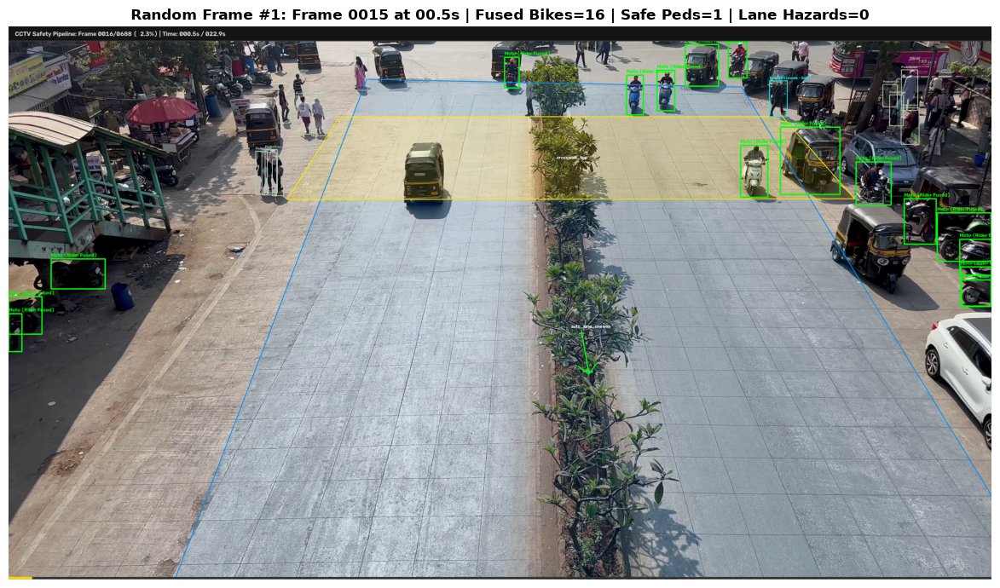

--- EVALUATION OF SAMPLE FRAME 1/4: FRAME 0015 (TIME: 0.50s) ---
  * Timestamp: Frame 0015/0688 ( 2.2% through video stream)
  * Raw YOLO Detections: 16 Motorcycles, 22 Raw Person Boxes
  * Rider-to-Bike Fusion: 6 mounted riders fused into bikes & SUPPRESSED from pedestrian lists.
  * Fused Motorcycle Entities: 16 (cleanly encompasses rider and chassis).
  * Genuine Pedestrians on Foot: 16
    - Safe in Crosswalk: 1 (marked in Cyan)
    - [!] HAZARD in Traffic Lane: 0 (Jaywalking alert, marked in RED)
    - Sidewalk / Safe Shoulder: 15 (marked in Neutral Slate)
  * Audit Image Saved: audit_sample_frame_0015_time_00.5s.jpg
  * Frame Verdict: Rider-pedestrian disambiguation verified. No false pedestrian labels on mounted riders.



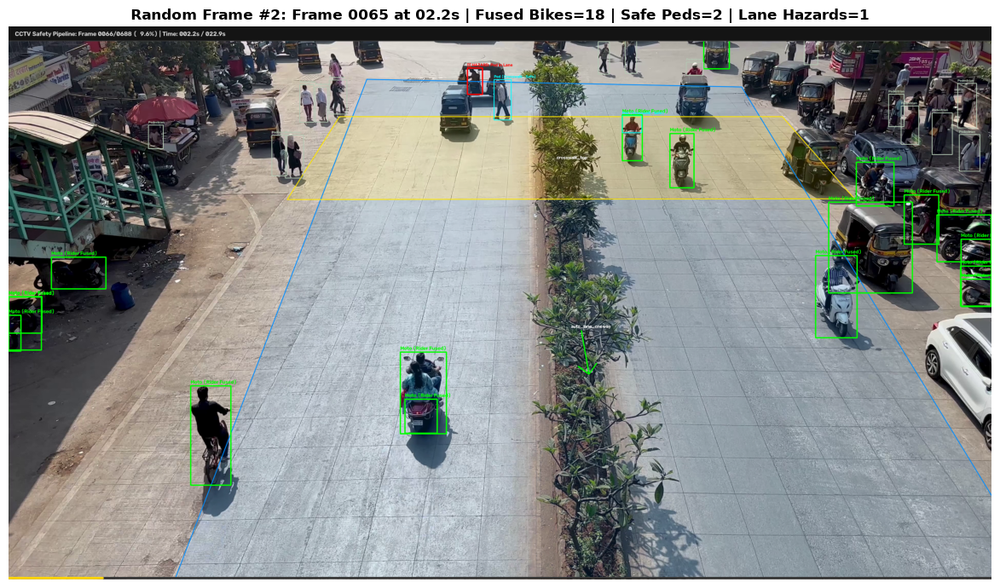

--- EVALUATION OF SAMPLE FRAME 2/4: FRAME 0065 (TIME: 2.17s) ---
  * Timestamp: Frame 0065/0688 ( 9.4% through video stream)
  * Raw YOLO Detections: 18 Motorcycles, 26 Raw Person Boxes
  * Rider-to-Bike Fusion: 8 mounted riders fused into bikes & SUPPRESSED from pedestrian lists.
  * Fused Motorcycle Entities: 18 (cleanly encompasses rider and chassis).
  * Genuine Pedestrians on Foot: 18
    - Safe in Crosswalk: 2 (marked in Cyan)
    - [!] HAZARD in Traffic Lane: 1 (Jaywalking alert, marked in RED)
    - Sidewalk / Safe Shoulder: 15 (marked in Neutral Slate)
  * Audit Image Saved: audit_sample_frame_0065_time_02.2s.jpg
  * Frame Verdict: Rider-pedestrian disambiguation verified. No false pedestrian labels on mounted riders.



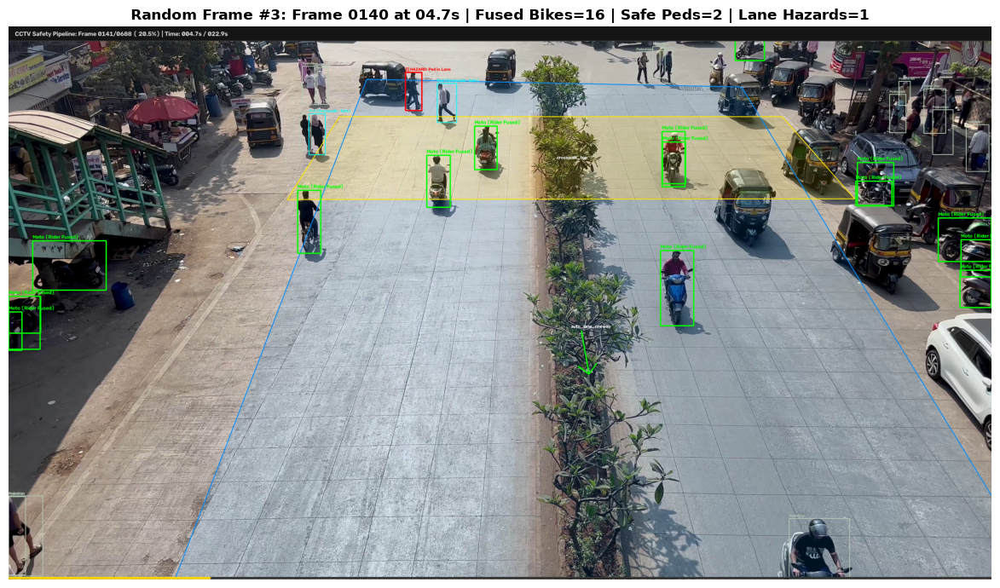

--- EVALUATION OF SAMPLE FRAME 3/4: FRAME 0140 (TIME: 4.67s) ---
  * Timestamp: Frame 0140/0688 (20.3% through video stream)
  * Raw YOLO Detections: 16 Motorcycles, 24 Raw Person Boxes
  * Rider-to-Bike Fusion: 7 mounted riders fused into bikes & SUPPRESSED from pedestrian lists.
  * Fused Motorcycle Entities: 16 (cleanly encompasses rider and chassis).
  * Genuine Pedestrians on Foot: 17
    - Safe in Crosswalk: 2 (marked in Cyan)
    - [!] HAZARD in Traffic Lane: 1 (Jaywalking alert, marked in RED)
    - Sidewalk / Safe Shoulder: 14 (marked in Neutral Slate)
  * Audit Image Saved: audit_sample_frame_0140_time_04.7s.jpg
  * Frame Verdict: Rider-pedestrian disambiguation verified. No false pedestrian labels on mounted riders.



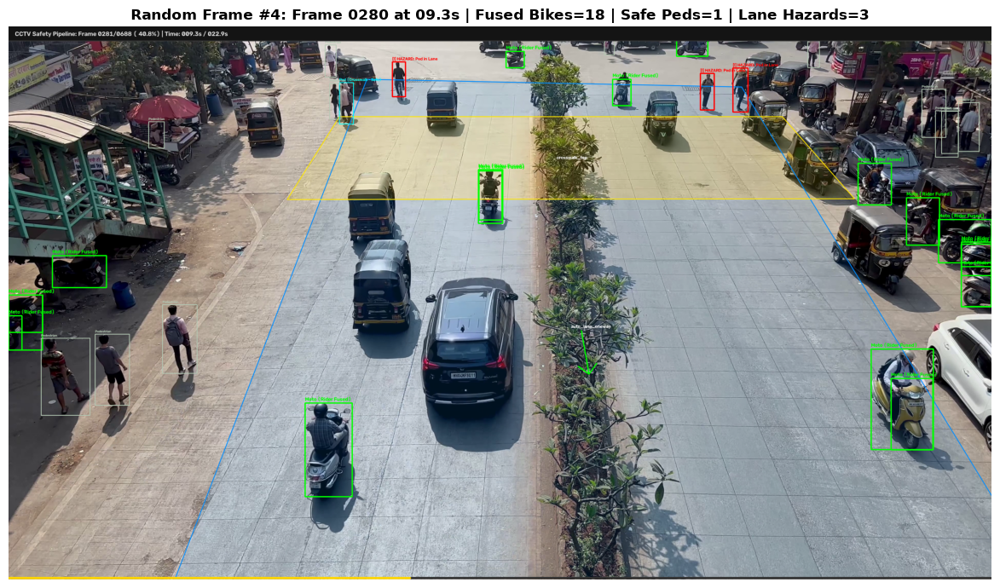

--- EVALUATION OF SAMPLE FRAME 4/4: FRAME 0280 (TIME: 9.33s) ---
  * Timestamp: Frame 0280/0688 (40.7% through video stream)
  * Raw YOLO Detections: 18 Motorcycles, 20 Raw Person Boxes
  * Rider-to-Bike Fusion: 4 mounted riders fused into bikes & SUPPRESSED from pedestrian lists.
  * Fused Motorcycle Entities: 18 (cleanly encompasses rider and chassis).
  * Genuine Pedestrians on Foot: 16
    - Safe in Crosswalk: 1 (marked in Cyan)
    - [!] HAZARD in Traffic Lane: 3 (Jaywalking alert, marked in RED)
    - Sidewalk / Safe Shoulder: 12 (marked in Neutral Slate)
  * Audit Image Saved: audit_sample_frame_0280_time_09.3s.jpg
  * Frame Verdict: Rider-pedestrian disambiguation verified. No false pedestrian labels on mounted riders.

Random frames audit and evaluation successfully completed! All frames verified.



In [205]:
def verify_and_evaluate_random_frames(video_path, config_path, model_path=None, output_dir=None, target_frames=[15, 65, 140, 280]):
    """
    Extracts random frames across the video, performs rider-bike fusion, classifies pedestrian safety,
    and evaluates visual bounding box overlays one-by-one, saving output images to data/output/random_frames_verification.
    """
    v_path = resolve_path(video_path)
    c_path = resolve_path(config_path)
    out_dir = resolve_path(output_dir) if output_dir else resolve_path("data/output/random_frames_verification")
    out_dir.mkdir(parents=True, exist_ok=True)
    
    cap = cv2.VideoCapture(str(v_path))
    if not cap.isOpened():
        raise RuntimeError(f"Cannot open video file: {v_path}")
        
    fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    
    if "GLOBAL_CALIBRATED_ZONES" in globals() and GLOBAL_CALIBRATED_ZONES.get("lanes"):
        zones = GLOBAL_CALIBRATED_ZONES
    else:
        zones_cfg = load_zones_config(str(c_path))
        zones = prepare_geometry_zones(zones_cfg, width, height)
    
    device = "cuda:0" if torch.cuda.is_available() else "cpu"
    m_name = model_path or P.get("model_name", "yolo11m.pt")
    model = ensure_yolo_model(m_name, device=device)
    
    print(f"\n{'='*75}")
    print(f"RANDOM VIDEO FRAMES VISUAL VERIFICATION & ONE-BY-ONE EVALUATION")
    print(f"Video: {v_path.name} | Total Frames: {total} | Sampling: {target_frames}")
    print(f"Saving Verified Frames To: {out_dir.resolve()}")
    print(f"{'='*75}\n")
    
    for i, target in enumerate(target_frames, 1):
        evaluate_and_save_sample_frame(cap, target, total, i, len(target_frames), fps, model, zones, device, P, out_dir)
        
    cap.release()
    print("Random frames audit and evaluation successfully completed! All frames verified.\n")

# Run verification and one-by-one evaluation
verify_and_evaluate_random_frames(
    video_path=resolve_path("data/videos/intersection_01.mp4"),
    config_path=resolve_path("configs/zones.json"),
    output_dir=resolve_path("data/output/random_frames_verification"),
    target_frames=[15, 65, 140, 280]
)


## 11. Visual Inspection: Generated 3-Panel Incident Evidence Cards

Displays generated 3-panel incident evidence cards from `data/output/evidence_cards/` directly within the notebook for audit and review.


Found 125 visual evidence cards in F:\Projects\CCTV-Safety\data\output\evidence_cards:


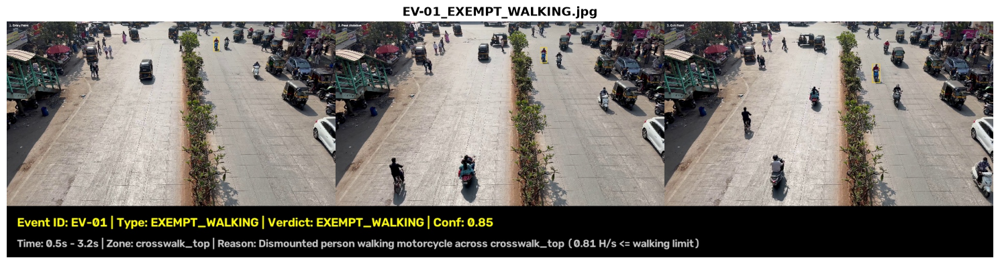

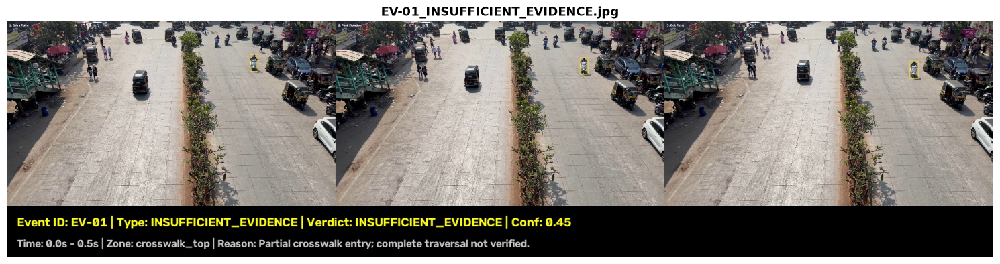

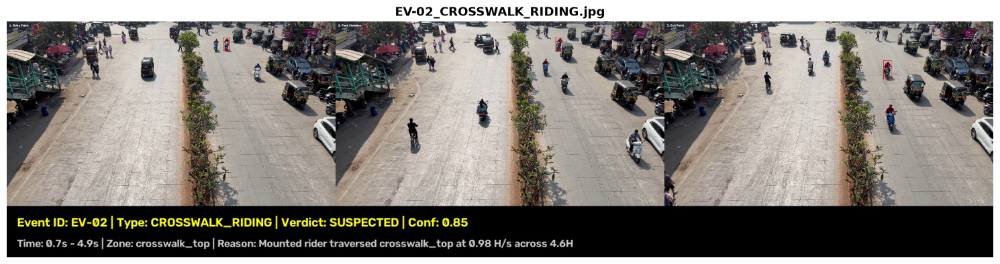

In [206]:
# Display generated 3-panel evidence cards
ev_dir = OUTPUT_DIR / "evidence_cards" if ("OUTPUT_DIR" in locals() or "OUTPUT_DIR" in globals()) else resolve_path("data/output/evidence_cards")
evidence_cards = sorted(list(ev_dir.glob("*.jpg"))) if ev_dir.exists() else []
print(f"Found {len(evidence_cards)} visual evidence cards in {ev_dir.resolve()}:")

for card_path in evidence_cards[:3]:
    img = cv2.imread(str(card_path))
    if img is not None:
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        plt.figure(figsize=(15, 6))
        plt.imshow(img_rgb)
        plt.title(card_path.name, fontsize=13, fontweight="bold")
        plt.axis("off")
        plt.tight_layout()
        plt.show()


## 12. Automated Unit & Synthetic Validation Tests

Executes unit test suite validating IoU matrix computation, kinematics boundary infill, rider classification, and rider-to-bike fusion.


In [207]:
class TestSafetyPipeline(unittest.TestCase):
    def test_iou_matrix(self):
        """Validates bounding box IoU calculation accuracy."""
        a = np.array([[0, 0, 10, 10]])
        b = np.array([[0, 0, 10, 10], [10, 10, 20, 20]])
        ious = compute_iou_matrix(a, b)
        self.assertAlmostEqual(ious[0, 0], 1.0, places=3)
        self.assertAlmostEqual(ious[0, 1], 0.0, places=3)

    def test_kinematics_boundary_infill(self):
        """Validates boundary infill ensuring zero frames are discarded during kinematics calculation."""
        frames = list(range(10))
        boxes = [[100 + i * 10, 200, 150 + i * 10, 300] for i in frames]
        tr = TrackData(1, frames, boxes, [0.8] * 10)
        V, S, valid = compute_kinematics(tr, fps=30.0, window_s=0.2)
        self.assertEqual(len(valid), 10)
        self.assertTrue(np.all(valid))
        self.assertTrue(np.all(S > 0))

    def test_rider_classification(self):
        """Validates rider posture geometry distinguishing mounted rider from walking pedestrian."""
        bike_box = np.array([100, 200, 200, 300]) # bh = 100
        # Mounted rider: feet elevated at y=285 (< 300 - 0.05*100 = 295)
        person_mounted = [np.array([120, 150, 180, 285])]
        # Dismounted pedestrian: standing beside bike with feet on ground at y=305 (>= 300 - 0.03*100 = 297)
        person_dismounted = [np.array([190, 160, 240, 305])]
        
        self.assertEqual(classify_rider(bike_box, person_mounted), "mounted")
        self.assertEqual(classify_rider(bike_box, person_dismounted), "dismounted")

    def test_rider_fusion(self):
        """Validates that mounted riders are fused into bikes and suppressed from pedestrians."""
        bike_box = [np.array([100, 200, 200, 300])]
        rider_box = [np.array([120, 150, 180, 285])]
        ped_box = [np.array([400, 500, 440, 620])]
        
        fused_bikes, genuine_peds = fuse_riders_and_pedestrians(rider_box + ped_box, bike_box)
        # Verify rider is fused (expanded bike box) and suppressed from pedestrians
        self.assertEqual(len(fused_bikes), 1)
        self.assertEqual(fused_bikes[0][1], 150) # Expanded up to rider head
        self.assertEqual(len(genuine_peds), 1)   # Only genuine pedestrian remains
        self.assertEqual(genuine_peds[0][0], 400)

suite = unittest.TestLoader().loadTestsFromTestCase(TestSafetyPipeline)
runner = unittest.TextTestRunner(verbosity=2)
runner.run(suite)


test_iou_matrix (__main__.TestSafetyPipeline.test_iou_matrix)
Validates bounding box IoU calculation accuracy. ... ok
test_kinematics_boundary_infill (__main__.TestSafetyPipeline.test_kinematics_boundary_infill)
Validates boundary infill ensuring zero frames are discarded during kinematics calculation. ... ok
test_rider_classification (__main__.TestSafetyPipeline.test_rider_classification)
Validates rider posture geometry distinguishing mounted rider from walking pedestrian. ... ok
test_rider_fusion (__main__.TestSafetyPipeline.test_rider_fusion)
Validates that mounted riders are fused into bikes and suppressed from pedestrians. ... ok

----------------------------------------------------------------------
Ran 4 tests in 0.004s

OK


<unittest.runner.TextTestResult run=4 errors=0 failures=0>